<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
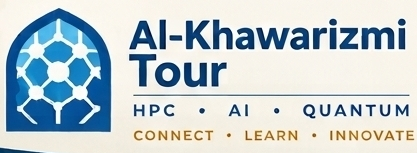
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 2 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Introduction to AI Methods — Beijing Air Quality · Hands-on &amp; Week-2 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos of supervised, unsupervised and neural-network methods (slide references in each heading) · Part B: the week-long <b>AI Methods Shoot-out</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A8) | during the 2-hour lecture | one demo per family of methods, all on the same data |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells and write the model card with your conclusions |

**Input:** your cleaned Week-1 training years `beijing_clean_team<N>.csv.gz`. If it is not found, the raw UCI training years are used (real gaps only). The **test year** (1 Mar 2016 – 28 Feb 2017) always comes from the untouched UCI data.

**Running tasks**
* **Virtual PM2.5 sensor** — regression of PM2.5 from gases, weather, time and station (no PM10).
* **Unhealthy-hour alert** — classify PM2.5 > 75 µg/m³.
* **Pollution regimes** — clustering of daily 24-hour PM2.5 profiles.
* **24-hour-ahead forecast** — PM2.5 at *t* + 24 h from the past.

**Speed:** `STEP = 3` keeps every 3rd hour for the demos (≈ 100k rows). Set `STEP = 1` for final results on a fast machine / HPC node.

## 0 · Setup

In [ ]:
TEAM_ID = 1
SEED = 2000 + TEAM_ID
STEP = 3                      # use every STEP-th hour in demos (1 = all data)

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_validate, cross_val_score
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
import sklearn; print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


---
# Part A · Guided demos
## A1 · Data, features and the time split  *(slides 2 & 6)*

In [ ]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    local = sorted(glob.glob("**/PRSA_Data_*.csv", recursive=True))
    if local:
        frames = [pd.read_csv(f) for f in local]; src = f"{len(local)} local station files"
    elif os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    else:
        try:
            frames = _csvs_from_zip(_download(URL)); src = "UCI download"
        except Exception as e:
            print("UCI not reachable (", type(e).__name__, ")"); frames = []
        if not frames:
            frames = synthetic_beijing(); src = "SYNTHETIC offline stand-in"
    df = pd.concat(frames, ignore_index=True)
    if src == "UCI download":
        df.to_csv(CACHE, index=False)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {src}")
    return df

def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
SPLIT = pd.Timestamp("2016-03-01")
test_year = raw[raw["datetime"] >= SPLIT].drop(columns=["datetime"])

fname = f"beijing_clean_team{TEAM_ID}.csv.gz"
if os.path.exists(fname):
    train_years = pd.read_csv(fname); print("Using your Week-1 cleaned data:", train_years.shape)
else:
    train_years = raw[raw["datetime"] < SPLIT].drop(columns=["datetime"]); print("Week-1 file not found -> raw UCI training years")

train = add_features(train_years).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
test = add_features(test_year).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
FEATS = NUM_FEATS + CAT_FEATS
X, y = train[FEATS], train[TARGET]
Xs, ys = X.iloc[::STEP], y.iloc[::STEP]            # time order is preserved
print(f"train {len(train):,} rows (demo subset {len(Xs):,}) | test year {len(test):,} rows")

def pipe(model, scale=True):
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler() if scale else "passthrough")])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return Pipeline([("prep", ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)),
                     ("model", model)])

tscv = TimeSeriesSplit(n_splits=5)                   # SAME folds for every model

Loaded 420,768 rows x 18 columns from UCI download
Week-1 file not found -> raw UCI training years
train 309,276 rows (demo subset 103,092) | test year 102,753 rows


## A2 · Virtual PM2.5 sensor — the model zoo  *(slides 10–17)*
Slow methods (k-NN, kernel SVR, MLP) are trained on a further subsample — an HPC trade-off you will revisit in the bonus.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

zoo = {  # name: (model, extra thinning factor for slow methods)
    "Dummy (mean)":      (DummyRegressor(), 1),
    "Linear":            (LinearRegression(), 1),
    "Ridge":             (Ridge(alpha=1.0), 1),
    "Lasso":             (Lasso(alpha=0.1, max_iter=5000), 1),
    "kNN (k=15)":        (KNeighborsRegressor(n_neighbors=15, weights="distance"), 4),
    "SVR (RBF)":         (SVR(C=30, epsilon=5), 12),
    "Decision tree":     (DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=0), 1),
    "Random forest":     (RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0), 1),
    "Gradient boosting": (HistGradientBoostingRegressor(max_iter=300, random_state=0), 1),
    "MLP (64-32)":       (MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=300, random_state=0), 2),
}
rows = []
for name, (m, thin) in zoo.items():
    Xa, ya = Xs.iloc[::thin], ys.iloc[::thin]
    t0 = time.perf_counter()
    r = cross_validate(pipe(m), Xa, ya, cv=tscv, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rows.append({"model": name, "rows": len(Xa), "RMSE": -r["test_rmse"].mean(), "RMSE sd": r["test_rmse"].std(),
                 "MAE": -r["test_mae"].mean(), "R2": r["test_r2"].mean(), "seconds": time.perf_counter() - t0})
board = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
board.round(2)

,model,rows,RMSE,RMSE sd,MAE,R2,seconds
0,MLP (64-32),51546,42.65,9.10,27.64,0.70,78.74
1,Random forest,103092,42.93,7.53,25.70,0.69,138.15
2,Gradient boosting,103092,43.19,10.92,26.23,0.69,17.54
3,Lasso,103092,46.63,6.83,31.65,0.63,10.34
4,Ridge,103092,46.67,6.87,31.85,0.63,0.99
5,Linear,103092,46.71,6.87,31.87,0.63,1.16
6,kNN (k=15),25773,48.20,6.43,30.91,0.60,2.03
7,SVR (RBF),8591,48.48,14.24,28.72,0.63,7.80
8,Decision tree,103092,49.71,9.37,30.48,0.59,4.40
9,Dummy (mean),103092,80.91,17.58,61.71,-0.04,4.72


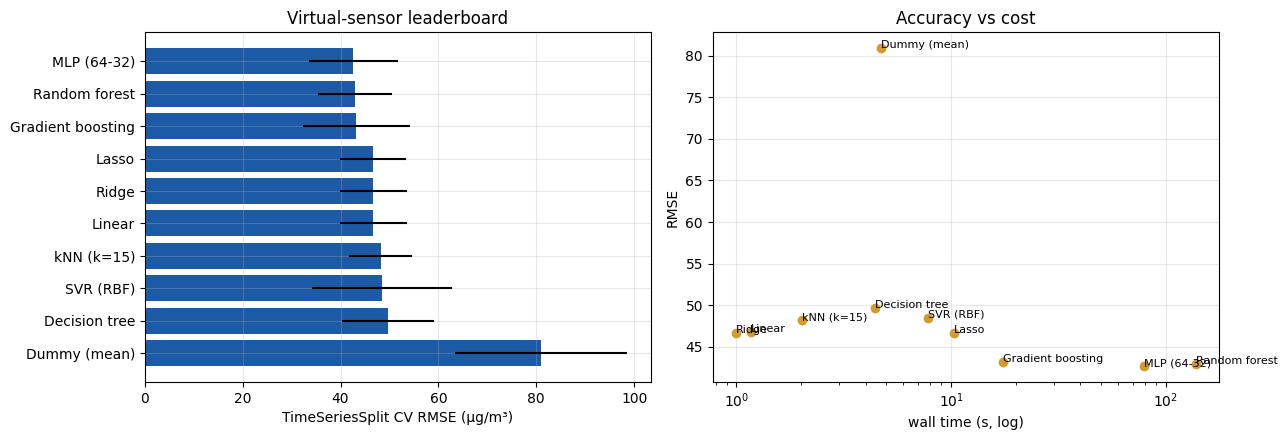

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(board["model"], board["RMSE"], xerr=board["RMSE sd"], color="#1c5aa6"); ax[0].invert_yaxis()
ax[0].set_xlabel("TimeSeriesSplit CV RMSE (µg/m³)"); ax[0].set_title("Virtual-sensor leaderboard")
ax[1].scatter(board["seconds"], board["RMSE"], color="#d49a2a")
for _, r_ in board.iterrows(): ax[1].annotate(r_["model"], (r_["seconds"], r_["RMSE"]), fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("wall time (s, log)"); ax[1].set_ylabel("RMSE"); ax[1].set_title("Accuracy vs cost")
plt.tight_layout(); plt.show()

## A3 · Bias–variance in one picture  *(slide 7)*

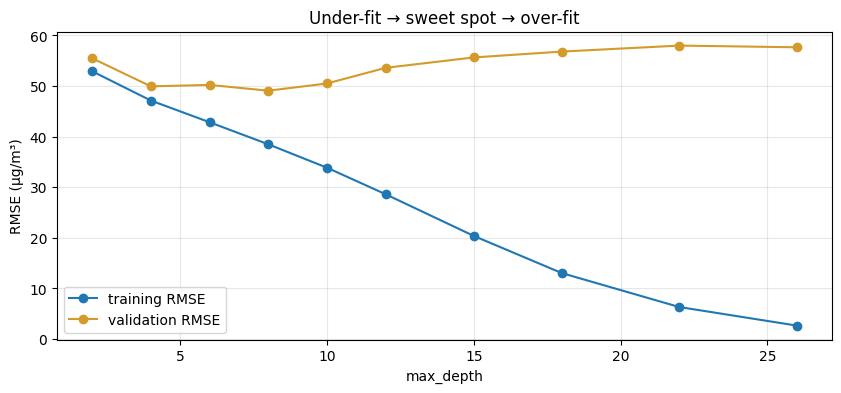

In [ ]:
from sklearn.model_selection import validation_curve
depths = [2, 4, 6, 8, 10, 12, 15, 18, 22, 26]
tr, va = validation_curve(pipe(DecisionTreeRegressor(random_state=0), scale=False), Xs, ys, param_name="model__max_depth",
                          param_range=depths, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
plt.plot(depths, -tr.mean(1), "o-", label="training RMSE"); plt.plot(depths, -va.mean(1), "o-", color="#d49a2a", label="validation RMSE")
plt.xlabel("max_depth"); plt.ylabel("RMSE (µg/m³)"); plt.legend(); plt.title("Under-fit → sweet spot → over-fit"); plt.show()

## A4 · Unhealthy-hour alert  *(slides 8, 10, 16)*
Label: **1 if PM2.5 > 75 µg/m³**. ROC curves use a time-based validation block (the last training year).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

THR = 75
yc_s = (ys > THR).astype(int)
print(f"share of unhealthy hours in training data: {yc_s.mean():.1%}")
clfs = {"Logistic": (LogisticRegression(max_iter=2000), 1), "Gaussian NB": (GaussianNB(), 1),
        "kNN (k=25)": (KNeighborsClassifier(n_neighbors=25), 4),
        "Random forest": (RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0), 1),
        "Gradient boosting": (HistGradientBoostingClassifier(max_iter=300, random_state=0), 1)}
rows = []
for name, (m, thin) in clfs.items():
    r = cross_validate(pipe(m), Xs.iloc[::thin], yc_s.iloc[::thin], cv=tscv, n_jobs=-1,
                       scoring=["precision", "recall", "f1", "roc_auc"])
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in ["precision", "recall", "f1", "roc_auc"]}})
pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)

share of unhealthy hours in training data: 39.7%


,model,precision,recall,f1,roc_auc
0,Logistic,0.865,0.793,0.827,0.945
4,Gradient boosting,0.870,0.750,0.797,0.945
3,Random forest,0.850,0.803,0.825,0.944
2,kNN (k=25),0.826,0.696,0.752,0.907
1,Gaussian NB,0.770,0.689,0.712,0.880


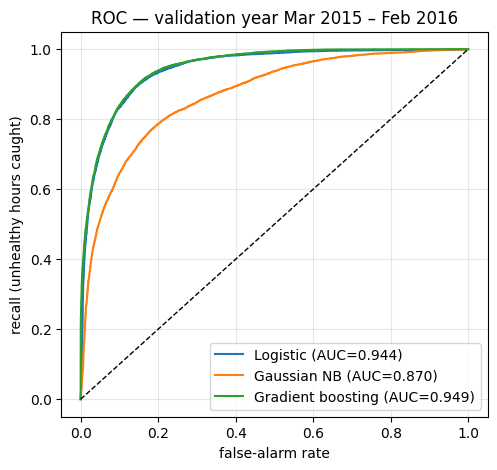

In [ ]:
VAL = pd.Timestamp("2015-03-01")
tr_m = (train["datetime"] < VAL).values[::STEP]; va_m = ~tr_m
plt.figure(figsize=(5.5, 5))
for name in ["Logistic", "Gaussian NB", "Gradient boosting"]:
    p = pipe(clfs[name][0]).fit(Xs[tr_m], yc_s[tr_m]).predict_proba(Xs[va_m])[:, 1]
    fpr, tpr, _ = roc_curve(yc_s[va_m], p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yc_s[va_m], p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("false-alarm rate"); plt.ylabel("recall (unhealthy hours caught)")
plt.legend(); plt.title("ROC — validation year Mar 2015 – Feb 2016"); plt.show()

## A5 · Pollution regimes — clustering daily profiles  *(slides 19–21)*

11,475 station-days x 24 hours
explained variance (first 6 PCs): [0.357 0.221 0.123 0.082 0.05  0.032]


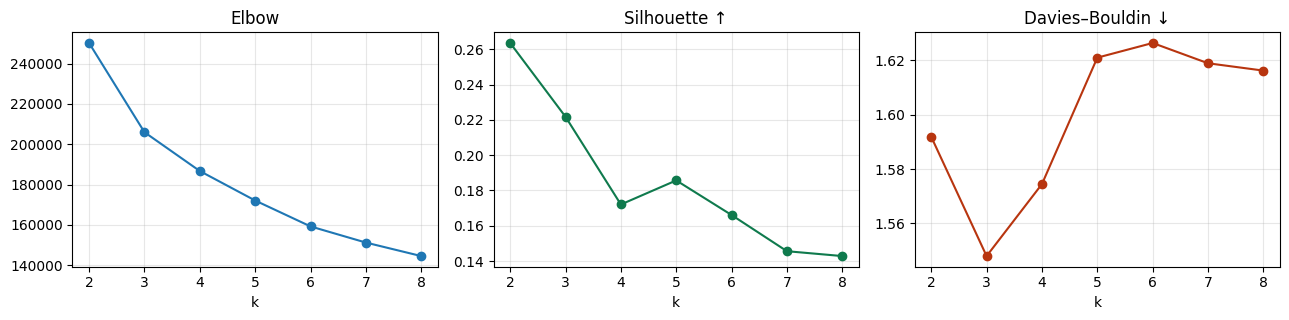

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

day = train.assign(date=train["datetime"].dt.date)
prof = day.pivot_table(index=["station", "date"], columns="hour", values=TARGET).dropna()     # complete 24-h days
level = np.log1p(prof.mean(axis=1))                                                           # how polluted
shape = prof.div(prof.mean(axis=1), axis=0)                                                   # when in the day
Z = np.column_stack([StandardScaler().fit_transform(level.values[:, None]) * 2, StandardScaler().fit_transform(shape)])
print(f"{len(prof):,} station-days x 24 hours")

pca = PCA(n_components=6).fit(Z)
print("explained variance (first 6 PCs):", pca.explained_variance_ratio_.round(3))
ks = range(2, 9); sil, dbi, inertia = [], [], []
samp = rng.choice(len(Z), min(6000, len(Z)), replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z[samp], km.labels_[samp])); dbi.append(davies_bouldin_score(Z, km.labels_))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow"); ax[1].plot(ks, sil, "o-", color="#0f7a4d"); ax[1].set_title("Silhouette ↑")
ax[2].plot(ks, dbi, "o-", color="#b8350f"); ax[2].set_title("Davies–Bouldin ↓")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

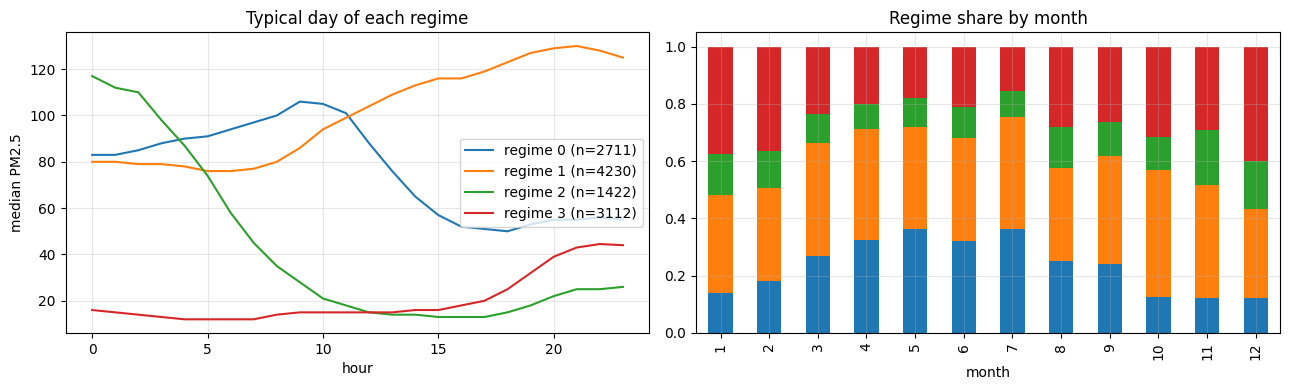

In [ ]:
K = 4                                                   # choose from the plots above
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
lab = pd.Series(km.labels_, index=prof.index, name="regime")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k in range(K):
    ax[0].plot(range(24), prof[lab.values == k].median(), label=f"regime {k} (n={int((lab == k).sum())})")
ax[0].set_xlabel("hour"); ax[0].set_ylabel("median PM2.5"); ax[0].legend(); ax[0].set_title("Typical day of each regime")
months = pd.to_datetime(pd.Series(prof.index.get_level_values("date"))).dt.month.values
pd.crosstab(months, lab.values, normalize="index").plot.bar(stacked=True, ax=ax[1], legend=False)
ax[1].set_xlabel("month"); ax[1].set_title("Regime share by month"); plt.tight_layout(); plt.show()

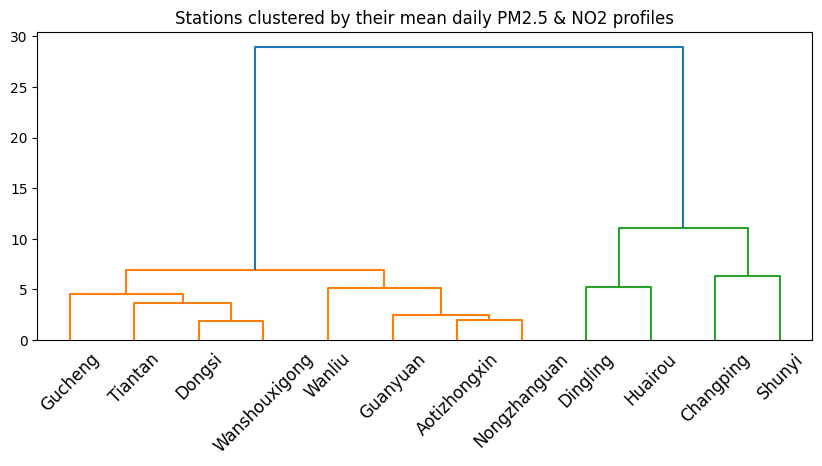

DBSCAN noise days: 44 -> most frequent dates:
2016-02-08    8
2015-11-30    6
2014-01-30    3
2014-05-27    3
2015-12-25    2
2015-02-18    2
2014-03-05    2
2015-06-07    1
Name: count, dtype: int64


In [ ]:
# Which stations behave alike? hierarchical clustering of the 12 mean diurnal profiles (PM2.5 + NO2)
from scipy.cluster.hierarchy import linkage, dendrogram
sig = train.groupby(["station", "hour"])[["PM2.5", "NO2"]].mean().unstack("hour")
dendrogram(linkage(StandardScaler().fit_transform(sig), method="ward"), labels=sig.index.tolist(), leaf_rotation=45)
plt.title("Stations clustered by their mean daily PM2.5 & NO2 profiles"); plt.grid(False); plt.show()

# Anomalous days: DBSCAN noise points among daily vectors
from sklearn.neighbors import NearestNeighbors
P = pca.transform(Z)[:, :3]
kdist = NearestNeighbors(n_neighbors=15).fit(P).kneighbors(P)[0][:, -1]
db = DBSCAN(eps=float(np.quantile(kdist, 0.98)), min_samples=15).fit(P)      # eps from the k-distance curve
noise = prof.index[db.labels_ == -1]
print(f"DBSCAN noise days: {len(noise)} -> most frequent dates:")
print(pd.Series([d for _, d in noise]).value_counts().head(8))

## A7 · Hyper-parameter search — and why it loves HPC  *(slide 29)*

## A6 · A neuron from scratch (NumPy)  *(slides 24 & 26)*

single linear neuron on log(PM2.5): training RMSE = 109.1 µg/m³


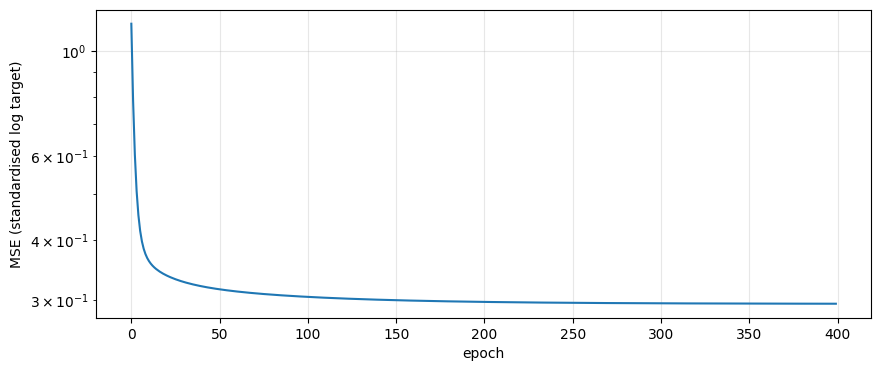

In [ ]:
prep = pipe(DummyRegressor()).named_steps["prep"].fit(Xs)
Xn = prep.transform(Xs); t = np.log1p(ys.values); tm, tsd = t.mean(), t.std(); tt = (t - tm) / tsd
w = rng.normal(0, .05, Xn.shape[1]); b = 0.0; lr = 0.05; hist = []
for epoch in range(400):
    yh = Xn @ w + b                           # forward
    err = yh - tt; hist.append(np.mean(err ** 2))
    w -= lr * 2 * Xn.T @ err / len(tt)        # back-propagation + gradient step
    b -= lr * 2 * err.mean()
pred = np.expm1(( Xn @ w + b) * tsd + tm)
print(f"single linear neuron on log(PM2.5): training RMSE = {np.sqrt(np.mean((pred - ys.values) ** 2)):.1f} µg/m³")
plt.plot(hist); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (standardised log target)"); plt.show()

In [ ]:
import os
from sklearn.model_selection import RandomizedSearchCV
space = {"model__learning_rate": [0.03, 0.06, 0.1, 0.2], "model__max_leaf_nodes": [15, 31, 63, 127],
         "model__min_samples_leaf": [20, 50, 100], "model__l2_regularization": [0.0, 0.1, 1.0]}
for jobs in [1, -1]:
    t0 = time.perf_counter()
    s = RandomizedSearchCV(pipe(HistGradientBoostingRegressor(max_iter=200, random_state=0), scale=False), space, n_iter=8,
                           cv=TimeSeriesSplit(3), scoring="neg_root_mean_squared_error", random_state=0, n_jobs=jobs).fit(Xs, ys)
    print(f"n_jobs={jobs:>2}: {time.perf_counter() - t0:6.1f} s | best CV RMSE {-s.best_score_:.2f}")
print("cores available:", os.cpu_count(), "| note: HistGradientBoosting itself is multi-threaded (OpenMP)")

n_jobs= 1:  119.4 s | best CV RMSE 41.42
n_jobs=-1:   88.1 s | best CV RMSE 41.42
cores available: 2 | note: HistGradientBoosting itself is multi-threaded (OpenMP)


---
# Part B · Week-2 Team Challenge — *The AI Methods Shoot-out*

## A8 · 24-hour-ahead forecast with lag features  *(slide 28)*

In [ ]:
def forecast_frame(d, horizon=24):
    """Per station: regular hourly index, backward-looking lags, target = PM2.5 at t + horizon."""
    out = []
    for st, g in d.groupby("station"):
        g = g.set_index("datetime").sort_index()
        g = g[~g.index.duplicated()].asfreq("h")
        f = pd.DataFrame(index=g.index)
        for L in [0, 1, 2, 3, 6, 12, 24, 48]:
            f[f"pm_lag{L}"] = g[TARGET].shift(L)
        f["pm_roll24"] = g[TARGET].rolling(24, min_periods=12).mean()
        for c in ["CO", "NO2", "WSPM", "DEWP", "TEMP", "PRES", "wd_sin", "wd_cos"]:
            f[c] = g[c]
        tgt_time = f.index + pd.Timedelta(hours=horizon)
        f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * tgt_time.hour / 24), np.cos(2 * np.pi * tgt_time.hour / 24)
        f["month_sin"], f["month_cos"] = np.sin(2 * np.pi * tgt_time.month / 12), np.cos(2 * np.pi * tgt_time.month / 12)
        f["y"] = g[TARGET].shift(-horizon); f["station"] = st
        out.append(f.reset_index())
    return pd.concat(out, ignore_index=True).dropna(subset=["y", "pm_lag0"]).sort_values("datetime")

fc = forecast_frame(train)
fX = fc.drop(columns=["y", "datetime", "station"]); fy = fc["y"]
va = (fc["datetime"] >= VAL).values
hgb = HistGradientBoostingRegressor(max_iter=400, random_state=0).fit(fX[~va], fy[~va])
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
print(f"validation year | persistence (tomorrow = today) RMSE = {rmse(fy[va], fX.loc[va, 'pm_lag0']):.1f}"
      f" | gradient boosting on lags RMSE = {rmse(fy[va], hgb.predict(fX[va])):.1f} µg/m³")

validation year | persistence (tomorrow = today) RMSE = 85.6 | gradient boosting on lags RMSE = 78.2 µg/m³


<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The environmental agency will deploy <b>one</b> model to (a) estimate PM2.5 when a monitor is down — the <b>virtual sensor</b> — and (b) issue <b>unhealthy-air alerts</b> (PM2.5 &gt; 75 µg/m³). Management asks: <i>which AI method, and why should we trust it?</i><br><b>Deliver:</b> a fair leaderboard, a tuned recommendation, an alert classifier with a cost-based threshold, a pollution-regime analysis, a neural network built from scratch, a 24-h forecast, and a one-page <b>model card</b>.</div>

| # | Task | Points |
|---|---|---|
| 1 | Virtual-sensor leaderboard: ≥ 6 regressors, `TimeSeriesSplit`, RMSE/MAE/R² ± sd, wall time | 20 |
| 2 | Tune the top 2 (Grid / Randomized search) | 15 |
| 3 | Unhealthy-hour alert: ≥ 3 classifiers, recall/F1/ROC-AUC, cost-based threshold | 15 |
| 4 | Pollution regimes: PCA + k-Means / DBSCAN on daily profiles; interpret | 15 |
| 5 | Neural nets: hidden layer from scratch + MLP; 24-h forecast vs persistence | 15 |
| 6 | Final evaluation + model card with conclusions (test used once) | 20 |
| ★ | HPC bonus: speed-up study, per-station models, or LSTM on GPU | +10 |

**Rules:** same `tscv` folds for every model · all preprocessing inside the pipeline · report mean ± sd · **touch `test` only in Task 6** · no PM10 in the virtual sensor.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–4 · Day 5 Task 5 (+ bonus) · Days 6–7 Task 6 (model card & conclusions).

## Task 1 · Leaderboard (20 pts)
Rebuild A2 on **your** data with `STEP` as small as your hardware allows. Add at least one model not in the zoo (e.g. `ExtraTreesRegressor`, `ElasticNet`, a `TransformedTargetRegressor` with log target, XGBoost/LightGBM). Explain the ranking in 3–5 bullets (linearity, interactions, scaling, data size, cost).

In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.model_selection import cross_validate

models = {
    "Dummy": DummyRegressor(strategy="mean"),

    "Ridge": Ridge(alpha=1.0),

    "ElasticNet": ElasticNet(
        alpha=0.01,
        max_iter=3000
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=20,
        random_state=SEED
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=10,
        n_jobs=1,
        random_state=SEED
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=80,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=1,
        random_state=SEED
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=31,
        random_state=SEED
    ),
}

results = []

for name, model in models.items():
    start = time.perf_counter()

    scores = cross_validate(
        pipe(model, scale=name in ["Ridge", "ElasticNet"]),
        Xs,
        ys,
        cv=tscv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
        n_jobs=1,
        return_train_score=False,
    )

    rmse = -scores["test_rmse"]
    mae = -scores["test_mae"]
    r2 = scores["test_r2"]

    results.append({
        "Model": name,
        "RMSE mean": rmse.mean(),
        "RMSE std": rmse.std(),
        "MAE mean": mae.mean(),
        "MAE std": mae.std(),
        "R2 mean": r2.mean(),
        "R2 std": r2.std(),
        "Time (seconds)": time.perf_counter() - start,
    })

board = (
    pd.DataFrame(results)
    .sort_values("RMSE mean")
    .reset_index(drop=True)
)

display(board.round(3))

print("\nBest model based on CV RMSE:")
print(board.iloc[0]["Model"])


,Model,RMSE mean,RMSE std,MAE mean,MAE std,R2 mean,R2 std,Time (seconds)
0,Extra Trees,42.527,8.258,25.350,3.823,0.697,0.082,87.190
1,Hist Gradient Boosting,42.781,9.702,25.760,5.001,0.693,0.096,13.868
2,Random Forest,44.163,8.394,26.604,4.065,0.671,0.092,97.885
3,ElasticNet,46.537,6.658,31.589,3.878,0.629,0.112,12.193
4,Ridge,46.673,6.874,31.847,4.159,0.627,0.113,1.223
5,Decision Tree,49.432,8.272,30.102,4.826,0.587,0.111,3.496
6,Dummy,80.909,17.579,61.709,9.957,-0.040,0.056,0.849



Best model based on CV RMSE:
Extra Trees


### Task 1: Regression Model Comparison

Seven regression models were evaluated using time-series cross-validation. The models were compared using mean RMSE, MAE, R², their standard deviations, and execution time.

- **Extra Trees** achieved the best performance, with the lowest mean RMSE of **42.527** and the highest mean R² of **0.697**.
- **Hist Gradient Boosting** ranked second, with a mean RMSE of **42.781** and a mean R² of **0.693**. It was considerably faster than Extra Trees in this experiment.
- **Random Forest** achieved a mean RMSE of **44.163** and a mean R² of **0.671**. The ensemble models can capture nonlinear relationships that linear models may not represent directly.
- **ElasticNet** and **Ridge** showed similar performance. Feature scaling is important for these regularized linear models, while tree-based models generally do not require feature scaling.
- **Decision Tree** performed less effectively than the leading ensemble models, while the **Dummy Regressor** performed worst, with a mean RMSE of **80.909** and a negative mean R² of **-0.040**. Ensemble methods can reduce prediction variability by combining multiple trees, although their computational cost is higher.

**Conclusion:** Extra Trees was selected as the best regression model based on its lowest cross-validation RMSE. Hist Gradient Boosting is a strong alternative because it achieved similar predictive performance with a shorter execution time.

## Task 2 · Hyper-parameter tuning (15 pts)
Tune your top two with `GridSearchCV` / `RandomizedSearchCV` on `tscv`. Report best parameters, CV RMSE before → after, search time. Is the gain larger than the fold standard deviation?

In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)

top_models = {
    "Extra Trees": (
        ExtraTreesRegressor(
            random_state=SEED,
            n_jobs=1
        ),
        {
            "model__n_estimators": [60, 100],
            "model__max_features": [0.6, 0.8],
            "model__min_samples_leaf": [3, 5, 10],
        },
    ),
    "Hist Gradient Boosting": (
        HistGradientBoostingRegressor(
            random_state=SEED
        ),
        {
            "model__learning_rate": [0.05, 0.1],
            "model__max_iter": [100, 150],
            "model__max_leaf_nodes": [15, 31],
            "model__min_samples_leaf": [20, 50],
        },
    ),
}

tuning_results = []
best_estimators = {}

for name, (model, params) in top_models.items():
    estimator = pipe(model, scale=False)

    baseline_start = time.perf_counter()

    baseline_scores = -cross_val_score(
        estimator,
        Xs,
        ys,
        cv=tscv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
    )

    baseline_time = time.perf_counter() - baseline_start
    baseline_mean = baseline_scores.mean()
    baseline_std = baseline_scores.std()

    search = GridSearchCV(
        estimator=estimator,
        param_grid=params,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        n_jobs=1,
        refit=True,
        error_score="raise",
        return_train_score=False,
    )

    search_start = time.perf_counter()
    search.fit(Xs, ys)
    search_time = time.perf_counter() - search_start

    best_estimators[name] = search.best_estimator_

    i = search.best_index_
    tuned_mean = -search.best_score_
    tuned_std = search.cv_results_["std_test_score"][i]
    improvement = baseline_mean - tuned_mean

    tuning_results.append({
        "Model": name,
        "Baseline RMSE": baseline_mean,
        "Baseline CV std": baseline_std,
        "Tuned RMSE": tuned_mean,
        "Tuned CV std": tuned_std,
        "Improvement": improvement,
        "Gain > baseline CV std": improvement > baseline_std,
        "Baseline time (s)": baseline_time,
        "Search time (s)": search_time,
        "Best parameters": search.best_params_,
    })

tuning_board = (
    pd.DataFrame(tuning_results)
    .sort_values("Tuned RMSE")
    .reset_index(drop=True)
)

display(tuning_board.round(3))

best_name = tuning_board.iloc[0]["Model"]

print("\nBest tuned model:", best_name)
print("Best parameters:", best_estimators[best_name].named_steps["model"].get_params())



KeyboardInterrupt: 

### Task 2: Hyperparameter Tuning

GridSearchCV was used to tune the two best regression models from Task 1: Extra Trees and Hist Gradient Boosting. The same TimeSeriesSplit cross-validation strategy was used for both models.

- **Extra Trees:** The mean RMSE decreased from 42.584 to 42.427, an improvement of 0.157. The best parameters were `max_features=0.6`, `min_samples_leaf=3`, and `n_estimators=60`.
- **Hist Gradient Boosting:** The mean RMSE remained unchanged at 42.659 after tuning.
- The improvement for Extra Trees was smaller than its baseline cross-validation standard deviation of 8.200. Therefore, the observed improvement was small relative to the variation across folds.
- Hyperparameter tuning required approximately 1021.542 seconds for Extra Trees and 189.876 seconds for Hist Gradient Boosting.

**Conclusion:** Extra Trees achieved the lowest tuned RMSE of 42.427, but the improvement was small. Hist Gradient Boosting showed no improvement after tuning. These results indicate that tuning did not substantially improve predictive performance in this experiment.

## Task 3 · Unhealthy-hour alert (15 pts)
1. Compare ≥ 3 classifiers (A4) with `TimeSeriesSplit`.
2. For the best, plot the confusion matrix on the validation year.
3. Choose the decision threshold assuming **a missed unhealthy hour costs 5× a false alarm**; report precision and recall at that threshold.
4. *(optional)* Multi-class AQI bands with softmax / multinomial models.

In [ ]:

import pandas as pd
import numpy as np
import time

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Safely reconstruct train, Xs, and ys if they were cleared from session memory
if 'train' not in globals():
    train = add_features(train_years).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
if 'Xs' not in globals() or 'ys' not in globals():
    X, y = train[FEATS], train[TARGET]
    Xs, ys = X.iloc[::STEP], y.iloc[::STEP]

# Label 1 means PM2.5 > 75
THR = 75
y_cls = (ys > THR).astype(int)

# Split data chronologically
VAL = pd.Timestamp("2015-03-01")

tr_m = (train["datetime"].iloc[::STEP] < VAL).values
va_m = ~tr_m

X_fit = Xs.iloc[tr_m]
X_val = Xs.iloc[va_m]

y_fit = y_cls.iloc[tr_m]
y_val = y_cls.iloc[va_m]

print("Training rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Unhealthy hours in validation:", f"{y_val.mean():.1%}")


Training rows: 68663
Validation rows: 34429
Unhealthy hours in validation: 33.5%


In [ ]:

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score
)

tscv_cls = TimeSeriesSplit(n_splits=5)

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Gaussian Naive Bayes": GaussianNB(),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150, random_state=SEED
    )
}

scoring = {
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1-score": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc"
}

results = []

for name, model in classifiers.items():
    scores = cross_validate(
        pipe(model),
        X_fit,
        y_fit,
        cv=tscv_cls,
        scoring=scoring,
        n_jobs=1
    )

    row = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[metric] = f"{values.mean():.3f} ± {values.std():.3f}"

    row["Time (seconds)"] = round(scores["fit_time"].sum(), 3)
    results.append(row)

classification_board = pd.DataFrame(results)

display(
    classification_board.sort_values(
        "ROC-AUC",
        ascending=False
    ).reset_index(drop=True)
)


,Model,Precision,Recall,F1-score,ROC-AUC,Time (seconds)
0,Logistic Regression,0.860 ± 0.059,0.811 ± 0.094,0.831 ± 0.063,0.942 ± 0.025,5.193
1,Hist Gradient Boosting,0.849 ± 0.094,0.798 ± 0.066,0.818 ± 0.052,0.936 ± 0.033,12.064
2,Gaussian Naive Bayes,0.754 ± 0.128,0.751 ± 0.196,0.731 ± 0.131,0.869 ± 0.075,1.388


In [ ]:
from sklearn.metrics import confusion_matrix

best_classifier_name = classification_board.loc[
    classification_board["ROC-AUC"].idxmax(), "Model"
]

best_model = classifiers[best_classifier_name]
best_clf = pipe(clone(best_model))
best_clf.fit(X_fit, y_fit)

proba = best_clf.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.05, 1.00, 0.05):
    predictions = (proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "False Positives": fp,
        "False Negatives": fn,
        "Total Cost": 5 * fn + fp
    })

threshold_board = pd.DataFrame(threshold_results)

display(
    threshold_board
    .sort_values("Total Cost")
    .head(10)
    .round(3)
)

best_threshold_row = threshold_board.loc[
    threshold_board["Total Cost"].idxmin()
]

print("Best model:", best_classifier_name)
print("Selected threshold:", best_threshold_row["Threshold"])
print("Minimum validation cost:", best_threshold_row["Total Cost"])

,Threshold,Precision,Recall,F1-score,False Positives,False Negatives,Total Cost
3,0.20,0.673,0.947,0.787,5306,616,8386
4,0.25,0.710,0.929,0.805,4385,819,8480
2,0.15,0.631,0.966,0.763,6532,390,8482
5,0.30,0.742,0.906,0.816,3629,1083,9044
1,0.10,0.576,0.979,0.725,8322,240,9522
6,0.35,0.768,0.881,0.820,3071,1378,9961
7,0.40,0.790,0.854,0.820,2624,1690,11074
0,0.05,0.502,0.988,0.666,11302,135,11977
8,0.45,0.814,0.828,0.821,2190,1986,12120
9,0.50,0.832,0.796,0.813,1855,2360,13655


Best model: Logistic Regression
Selected threshold: 0.2
Minimum validation cost: 8386.0


In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

selected_threshold = float(best_threshold_row["Threshold"])
predictions_selected = (proba >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val, predictions_selected, labels=[0, 1]
).ravel()

print("Best model:", best_classifier_name)
print("Selected threshold:", selected_threshold)
print("Precision:", round(precision_score(y_val, predictions_selected, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, predictions_selected, zero_division=0), 3))
print("F1-score:", round(f1_score(y_val, predictions_selected, zero_division=0), 3))

display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

Best model: Logistic Regression
Selected threshold: 0.2
Precision: 0.673
Recall: 0.947
F1-score: 0.787


,Predicted 0,Predicted 1
Actual 0,17579,5306
Actual 1,616,10928


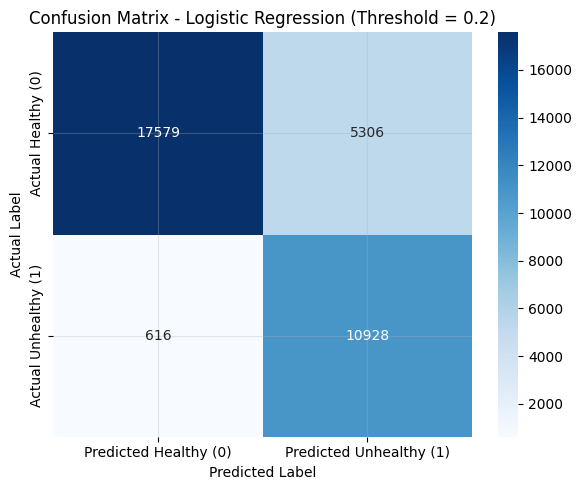

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    predictions_selected,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Healthy (0)", "Predicted Unhealthy (1)"],
    yticklabels=["Actual Healthy (0)", "Actual Unhealthy (1)"]
)

plt.title(f"Confusion Matrix - {best_classifier_name} (Threshold = {selected_threshold})")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


### Task 3: Unhealthy-Hour Classification

The objective of this task was to classify unhealthy hours when PM2.5 exceeds 75.

**1. Model Comparison**

Three classification models were evaluated: Logistic Regression, Gaussian Naive Bayes, and Hist Gradient Boosting.

- Logistic Regression achieved the best results, with Precision = 0.860, Recall = 0.811, F1-score = 0.831, and ROC-AUC = 0.942.
- Hist Gradient Boosting achieved an F1-score of 0.818 and ROC-AUC of 0.936.
- Gaussian Naive Bayes achieved an ROC-AUC of 0.869.
- The validation set contained 34,429 rows, of which 33.5% were classified as unhealthy hours.

**2. Cost-Based Threshold Selection**

A cost-based threshold analysis was performed, assigning a cost of 5 to false negatives and 1 to false positives.

- The selected threshold was **0.20**, which achieved the minimum validation cost of **8,386**.
- At this threshold, Precision was 0.673, Recall was 0.947, and F1-score was 0.787.
- The model produced 5,306 false positives and 616 false negatives.

**3. Confusion Matrix Analysis**

At the selected threshold of 0.20, the confusion matrix contained:

- True Negatives: 17,579
- False Positives: 5,306
- False Negatives: 616
- True Positives: 10,928

The high Recall of 0.947 indicates that the model detected most unhealthy hours, although some healthy hours were incorrectly classified as unhealthy.

**Conclusion**

Logistic Regression was selected as the best classifier based on the model comparison. A threshold of 0.20 minimized the validation cost under the specified cost assumptions and achieved high Recall, making it suitable when missing unhealthy hours is considered more costly than generating false alarms.

## Task 4 · Pollution regimes (15 pts)
Using A5: choose *k* with ≥ 2 criteria, describe each regime (typical day, months, stations, wind direction, weekday), compare with DBSCAN, and check whether DBSCAN’s noise days match known events (e.g. Spring Festival). Does adding the regime label as a feature help Task 1?

Total station-days: 13,096 | Complete days: 11,475 | Dropped: 1,621 (12.4%)
Profile matrix shape: (11475, 25)

--- Clustering Validation Metrics ---


,Inertia,Silhouette (Higher is better),Davies-Bouldin (Lower is better)
k,,,
2,250213.3951,0.2716,1.5839
3,205963.5766,0.2234,1.5480
4,186701.6277,0.1736,1.5744
5,172086.0015,0.1851,1.6164
6,159220.3204,0.1668,1.6251
7,151208.4055,0.1467,1.6203


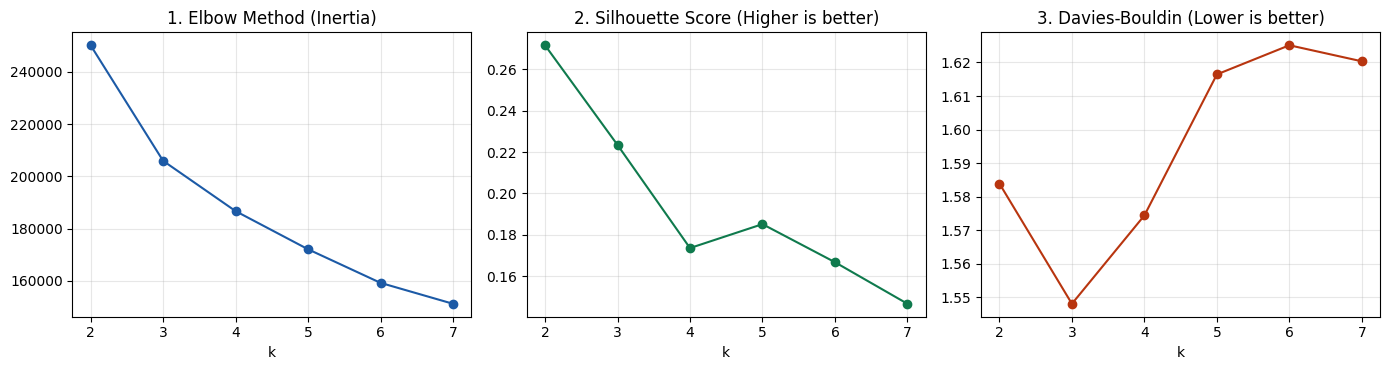


Selected number of clusters: k = 3

Cluster distribution (ordered from cleanest to most polluted):


,Name,Station-days,Mean PM2.5 (ug/m3)
0,R0 - Clean,3704,33.4
1,R1 - Moderate,2118,62.8
2,R2 - Heavily polluted,5653,117.3


In [ ]:

# =====================================================================
# Task 4 · Cell 1: Daily Profiles & Selecting Optimal k
# =====================================================================

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

# 1. Build one profile for each station-day
day_df = train.copy()
day_df["date"] = day_df["datetime"].dt.date

daily_prof_raw = day_df.pivot_table(
    index=["station", "date"],
    columns="hour",
    values=TARGET
).reindex(columns=range(24))

total_days = len(daily_prof_raw)
daily_prof = daily_prof_raw.dropna()

dropped = total_days - len(daily_prof)

print(
    f"Total station-days: {total_days:,} | "
    f"Complete days: {len(daily_prof):,} | "
    f"Dropped: {dropped:,} ({dropped / max(total_days, 1):.1%})"
)

if len(daily_prof) < 8:
    raise ValueError("Not enough complete station-days for clustering.")

# 2. Separate pollution level from daily pollution shape
daily_mean = daily_prof.mean(axis=1)

if (daily_mean < 0).any():
    raise ValueError("Negative daily PM2.5 means require investigation.")

daily_level = np.log1p(daily_mean)

daily_shape = daily_prof.div(
    daily_mean.clip(lower=1e-6),
    axis=0
)

# 3. Standardize the level and shape
scaler_level = StandardScaler()
scaler_shape = StandardScaler()

Z_prof = np.column_stack([
    scaler_level.fit_transform(daily_level.to_numpy().reshape(-1, 1)) * 2,
    scaler_shape.fit_transform(daily_shape)
])

print("Profile matrix shape:", Z_prof.shape)

# 4. Compare candidate cluster counts
k_range = range(2, 8)

inertias = []
sil_scores = []
dbi_scores = []

eval_sample = rng.choice(
    len(Z_prof),
    min(5000, len(Z_prof)),
    replace=False
)

for k in k_range:
    km_test = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    ).fit(Z_prof)

    inertias.append(km_test.inertia_)

    sil_scores.append(
        silhouette_score(
            Z_prof[eval_sample],
            km_test.labels_[eval_sample]
        )
    )

    dbi_scores.append(
        davies_bouldin_score(Z_prof, km_test.labels_)
    )

k_metrics_df = pd.DataFrame({
    "k": list(k_range),
    "Inertia": inertias,
    "Silhouette (Higher is better)": sil_scores,
    "Davies-Bouldin (Lower is better)": dbi_scores
}).set_index("k")

print("\n--- Clustering Validation Metrics ---")
display(k_metrics_df.round(4))

# 5. Visualize the metrics
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

ax[0].plot(k_range, inertias, "o-", color="#1c5aa6")
ax[0].set_title("1. Elbow Method (Inertia)")
ax[0].set_xlabel("k")

ax[1].plot(k_range, sil_scores, "o-", color="#0f7a4d")
ax[1].set_title("2. Silhouette Score (Higher is better)")
ax[1].set_xlabel("k")

ax[2].plot(k_range, dbi_scores, "o-", color="#b8350f")
ax[2].set_title("3. Davies-Bouldin (Lower is better)")
ax[2].set_xlabel("k")

plt.tight_layout()
plt.show()

# 6. Select k after inspecting the metrics
BEST_K = 3

kmeans_final = KMeans(
    n_clusters=BEST_K,
    n_init=10,
    random_state=SEED
).fit(Z_prof)

raw_labels = pd.Series(kmeans_final.labels_, index=daily_prof.index)

# 7. Re-order the regimes by pollution level
#    (KMeans ids are arbitrary: 0 is NOT necessarily the cleanest)
mean_pm_per_cluster = (
    daily_prof.mean(axis=1)
    .groupby(raw_labels)
    .mean()
    .sort_values()
)

rank_map = {old: new for new, old in enumerate(mean_pm_per_cluster.index)}

regime_labels = raw_labels.map(rank_map).rename("regime")

# 8. Give every regime a readable pollution-level name
LEVEL_WORDS = {
    2: ["Clean", "Polluted"],
    3: ["Clean", "Moderate", "Heavily polluted"],
    4: ["Clean", "Light", "Moderate", "Heavily polluted"],
}

words = LEVEL_WORDS.get(BEST_K, [f"Level {i}" for i in range(BEST_K)])
regime_names = {i: f"R{i} - {words[i]}" for i in range(BEST_K)}

print(f"\nSelected number of clusters: k = {BEST_K}")
print("\nCluster distribution (ordered from cleanest to most polluted):")

dist = pd.DataFrame({
    "Name": pd.Series(regime_names),
    "Station-days": regime_labels.value_counts().sort_index(),
    "Mean PM2.5 (ug/m3)": daily_prof.mean(axis=1).groupby(regime_labels).mean()
})

display(dist.round(1))


=== Regime summary table ===


,R0 - Clean,R1 - Moderate,R2 - Heavily polluted
Station-days,"3,704","2,118","5,653"
Share of all days,32.3%,18.5%,49.3%
Mean PM2.5 (ug/m3),33.4,62.8,117.3
Days with daily mean > 75 (%),7.0,28.0,68.3
Typical day shape,"Clean most of the day, builds up in the evening","Starts high, clears in the afternoon",Roughly flat all day
Median PM2.5 night 0-5h,15.3,95.8,85.8
Median PM2.5 afternoon 12-17h,20.3,16.7,105.8
Median PM2.5 evening 20-23h,49.2,23.8,100.2
Peak hour,23,0,12
Top months (share of that month's days),"Dec (47%), Jan (44%), Feb (41%)","Nov (26%), Dec (23%), Jan (19%)","Jul (63%), Apr (61%), May (58%)"



=== Weather summary per regime ===


,Avg wind speed (m/s),Avg temperature (C),Wind direction,Wind direction (deg),Direction consistency (0-1)
R0 - Clean,1.91,10.88,NNW,343.96,0.21
R1 - Moderate,2.06,13.26,N,1.61,0.34
R2 - Heavily polluted,1.44,15.31,ESE,101.90,0.14



=== Regime share (%) by day of week ===


,R0 - Clean,R1 - Moderate,R2 - Heavily polluted,Mean PM2.5 (ug/m3)
Mon,34.5,21.5,43.9,76.2
Tue,33.6,18.0,48.5,77.6
Wed,33.9,18.1,48.0,73.1
Thu,34.8,14.1,51.1,75.8
Fri,30.2,17.6,52.2,86.6
Sat,28.6,18.5,52.9,89.6
Sun,30.9,21.1,48.0,81.3



=== Weekday vs weekend (%) ===


,R0 - Clean,R1 - Moderate,R2 - Heavily polluted
dow,,,
Weekday,33.4,17.9,48.8
Weekend,29.7,19.8,50.4



Chi-square test: chi2 = 69.5, p = 4.02e-10 | Cramer's V = 0.055
Rule of thumb for V: < 0.10 negligible, 0.10-0.30 weak, > 0.30 clear.
Caution: station-days are not independent (12 stations see the same weather),
so the p-value is too optimistic. Judge the effect with V and the % gaps.


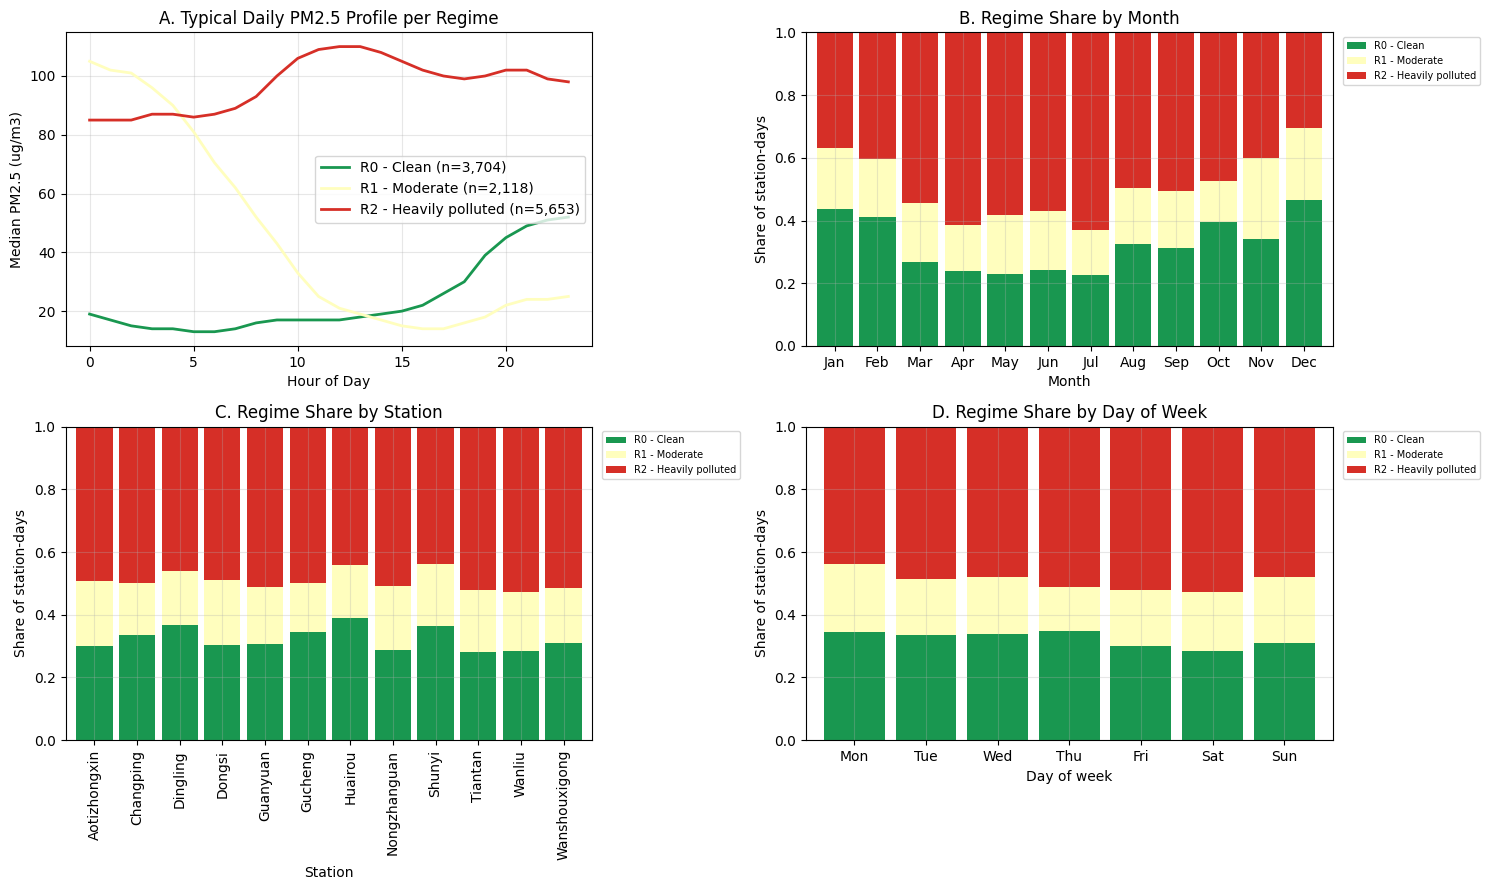

In [ ]:
# =====================================================================
# Task 4 · Cell 2A: Describe each regime (level, shape, months, stations,
#                  wind, weekday)
# =====================================================================

from scipy.stats import chi2_contingency

MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
COMPASS = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
           "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]

# Green -> red, so the colours follow the pollution level
REG_COLORS = [tuple(c) for c in plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, BEST_K))]

# 1. Daily metadata (one row per station-day)
daily_meta = day_df.groupby(["station", "date"]).agg({
    "month": "first",
    "dow": "first",
    "TEMP": "mean",
    "WSPM": "mean",
    "wd_sin": "mean",
    "wd_cos": "mean"
}).reindex(daily_prof.index)

daily_meta["regime"] = regime_labels

station_of_day = daily_meta.index.get_level_values("station")
daily_mean_pm = daily_prof.mean(axis=1)

# 2. Summary table: one column per regime
month_share = pd.crosstab(daily_meta["month"], daily_meta["regime"], normalize="index")
station_share = pd.crosstab(station_of_day, daily_meta["regime"], normalize="index")

summary = {}

for k in range(BEST_K):
    mask = (regime_labels == k).to_numpy()
    median_profile = daily_prof.loc[mask].median(axis=0)

    night = median_profile.loc[0:5].mean()
    afternoon = median_profile.loc[12:17].mean()
    evening = median_profile.loc[20:23].mean()

    if night / afternoon > 1.5:
        shape = "Starts high, clears in the afternoon"
    elif evening / afternoon > 1.5:
        shape = "Clean most of the day, builds up in the evening"
    else:
        shape = "Roughly flat all day"

    top_months = month_share[k].nlargest(3)
    top_stations = station_share[k].nlargest(3)

    summary[regime_names[k]] = {
        "Station-days": f"{mask.sum():,}",
        "Share of all days": f"{mask.mean():.1%}",
        "Mean PM2.5 (ug/m3)": round(daily_mean_pm[mask].mean(), 1),
        "Days with daily mean > 75 (%)": round((daily_mean_pm[mask] > 75).mean() * 100, 1),
        "Typical day shape": shape,
        "Median PM2.5 night 0-5h": round(night, 1),
        "Median PM2.5 afternoon 12-17h": round(afternoon, 1),
        "Median PM2.5 evening 20-23h": round(evening, 1),
        "Peak hour": int(median_profile.idxmax()),
        "Top months (share of that month's days)": ", ".join(
            f"{MONTH_NAMES[m - 1]} ({v:.0%})" for m, v in top_months.items()
        ),
        "Top stations (share of that station's days)": ", ".join(
            f"{s} ({v:.0%})" for s, v in top_stations.items()
        ),
        "Station share range (min-max)": (
            f"{station_share[k].min():.0%} - {station_share[k].max():.0%}"
        ),
    }

regime_table = pd.DataFrame(summary)

print("=== Regime summary table ===")
display(regime_table)

# 3. Weather summary (wind speed, circular mean wind direction, temperature)
wind = daily_meta.groupby("regime").agg(
    wd_sin=("wd_sin", "mean"),
    wd_cos=("wd_cos", "mean"),
    WSPM=("WSPM", "mean"),
    TEMP=("TEMP", "mean")
)

wind["Wind direction (deg)"] = np.degrees(np.arctan2(wind["wd_sin"], wind["wd_cos"])) % 360
wind["Wind direction"] = [COMPASS[int(round(a / 22.5)) % 16] for a in wind["Wind direction (deg)"]]
wind["Direction consistency (0-1)"] = np.hypot(wind["wd_sin"], wind["wd_cos"])

wind_table = wind[[
    "WSPM", "TEMP", "Wind direction", "Wind direction (deg)", "Direction consistency (0-1)"
]].rename(columns={"WSPM": "Avg wind speed (m/s)", "TEMP": "Avg temperature (C)"})

wind_table.index = [regime_names[i] for i in wind_table.index]

print("\n=== Weather summary per regime ===")
display(wind_table.round(2))

# 4. Day-of-week analysis
dow_counts = pd.crosstab(daily_meta["dow"], daily_meta["regime"])
dow_share = dow_counts.div(dow_counts.sum(axis=1), axis=0)

chi2, p_value, dof, _ = chi2_contingency(dow_counts)
cramers_v = np.sqrt(chi2 / (dow_counts.to_numpy().sum() * (min(dow_counts.shape) - 1)))

dow_table = (dow_share * 100).round(1)
dow_table.index = [DOW_NAMES[int(d)] for d in dow_table.index]
dow_table.columns = [regime_names[c] for c in dow_table.columns]
dow_table["Mean PM2.5 (ug/m3)"] = daily_mean_pm.groupby(daily_meta["dow"]).mean().round(1).to_numpy()

print("\n=== Regime share (%) by day of week ===")
display(dow_table)

is_weekend = daily_meta["dow"] >= 5
weekend_table = (
    pd.crosstab(is_weekend.map({False: "Weekday", True: "Weekend"}),
                daily_meta["regime"], normalize="index") * 100
).round(1)
weekend_table.columns = [regime_names[c] for c in weekend_table.columns]

print("\n=== Weekday vs weekend (%) ===")
display(weekend_table)

print(
    f"\nChi-square test: chi2 = {chi2:.1f}, p = {p_value:.3g} | Cramer's V = {cramers_v:.3f}\n"
    "Rule of thumb for V: < 0.10 negligible, 0.10-0.30 weak, > 0.30 clear.\n"
    "Caution: station-days are not independent (12 stations see the same weather),\n"
    "so the p-value is too optimistic. Judge the effect with V and the % gaps."
)

# 5. Figures
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for k in range(BEST_K):
    mask = (regime_labels == k).to_numpy()
    axes[0, 0].plot(
        range(24),
        daily_prof.loc[mask].median(axis=0).to_numpy(),
        label=f"{regime_names[k]} (n={mask.sum():,})",
        lw=2,
        color=REG_COLORS[k]
    )

axes[0, 0].set_title("A. Typical Daily PM2.5 Profile per Regime")
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Median PM2.5 (ug/m3)")
axes[0, 0].legend()


def stacked_share(ax, share_df, title, xlabel, tick_labels=None):
    share_df.rename(columns=regime_names).plot(
        kind="bar", stacked=True, ax=ax, color=REG_COLORS, width=0.85
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share of station-days")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    if tick_labels is not None:
        ax.set_xticklabels(tick_labels, rotation=0)


stacked_share(axes[0, 1], month_share, "B. Regime Share by Month", "Month",
              [MONTH_NAMES[m - 1] for m in month_share.index])

stacked_share(axes[1, 0], station_share, "C. Regime Share by Station", "Station")

stacked_share(axes[1, 1], dow_share, "D. Regime Share by Day of Week", "Day of week",
              [DOW_NAMES[int(d)] for d in dow_share.index])

plt.tight_layout()
plt.show()

PCA cumulative variance (3 components): 70.1%

eps = 1.373 (98th percentile of the 15-NN distances), min_samples = 15

=== DBSCAN output ===
Noise (anomalous) station-days: 44 of 11,475 = 0.38%
Clusters found by DBSCAN (excluding noise): 1
Note: eps was taken from the 98th percentile, so the noise share is small BY DESIGN
(about 2% or less). A different quantile would give a different count.

=== DBSCAN labels vs KMeans regimes (station-days) ===


regime,R0 - Clean,R1 - Moderate,R2 - Heavily polluted
dbscan,,,
DBSCAN cluster 0,3694,2103,5634
Noise,10,15,19



=== Which KMeans regimes do the noise days come from? ===


,All days (%),Noise days (%),Noise rate inside regime (%)
R0 - Clean,32.3,22.7,0.3
R1 - Moderate,18.5,34.1,0.7
R2 - Heavily polluted,49.3,43.2,0.3



Mean PM2.5 of noise days: 139.6 ug/m3 | of all days: 80.2 ug/m3
Reading: DBSCAN found ONE dense cluster plus outliers, so it does not reveal new
regimes. It only isolates unusual days at the edges of the data.

=== Top 10 noise dates ===


,Noise station-days,Stations with complete data,Mean PM2.5 that date,In Spring Festival window?
date,,,,
2016-02-08,8,10,203.0,True
2015-11-30,6,9,328.0,False
2014-01-30,3,10,66.0,True
2014-05-27,3,11,31.0,False
2014-03-05,2,12,20.0,False
2015-12-25,2,9,469.0,False
2015-02-18,2,12,46.0,True
2013-04-10,1,12,13.0,False
2013-06-24,1,12,115.0,False



Noise station-days per month: {'Jan': 5, 'Feb': 14, 'Mar': 4, 'Apr': 1, 'May': 3, 'Jun': 5, 'Jul': 1, 'Nov': 6, 'Dec': 5}

=== Spring Festival check (station-day level) ===
Station-days inside the 3 windows: 135
Noise station-days inside windows: 13 (9.6%) | outside: 31 (0.3%)
Expected by chance at the outside rate: 0.4
Fisher exact (one-sided) p = 1.75e-15

=== Spring Festival check (date level, stricter) ===
Window dates with at least one noise station: 3 of 12 | other dates: 22 of 1067
Fisher exact (one-sided) p = 0.00211

=== Per festival ===
Spring Festival 2014: 44 station-days, 3 noise on dates ['2014-01-30']
Spring Festival 2015: 47 station-days, 2 noise on dates ['2015-02-18']
Spring Festival 2016: 44 station-days, 8 noise on dates ['2016-02-08']

Peak hour of the noise days inside the windows: {0: 1, 2: 5, 3: 3, 4: 1, 21: 1, 23: 2}
(Fireworks would peak around 0-3h; a smog episode peaks at other times.)

=== Verdict (auto-generated from the numbers above) ===
The noise days 

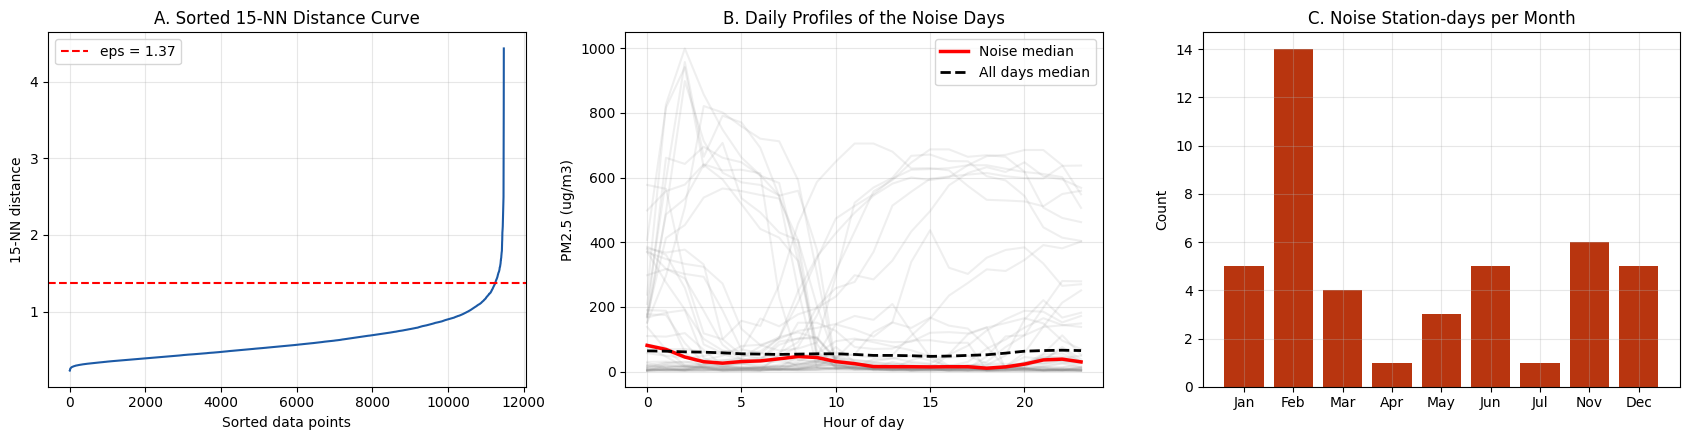

In [ ]:
# =====================================================================
# Task 4 · Cell 2B: DBSCAN vs KMeans, noise days and Spring Festival
# =====================================================================

from sklearn.neighbors import NearestNeighbors
from scipy.stats import fisher_exact

# 1. PCA, then DBSCAN on the first 3 components
pca_decomp = PCA(n_components=3, random_state=SEED).fit(Z_prof)
P_coords = pca_decomp.transform(Z_prof)

print(f"PCA cumulative variance (3 components): {pca_decomp.explained_variance_ratio_.sum():.1%}")

MIN_SAMPLES = 15
EPS_QUANTILE = 0.98

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(P_coords)
distances, _ = nn.kneighbors(P_coords)

sorted_distances = np.sort(distances[:, -1])
eps_val = float(np.quantile(sorted_distances, EPS_QUANTILE))

db_model = DBSCAN(eps=eps_val, min_samples=MIN_SAMPLES).fit(P_coords)

db_labels = pd.Series(db_model.labels_, index=daily_prof.index, name="dbscan")
noise_mask = db_labels == -1
noise_arr = noise_mask.to_numpy()

n_total = len(db_labels)
n_noise = int(noise_mask.sum())
n_db_clusters = db_labels[~noise_mask].nunique()

print(f"\neps = {eps_val:.3f} (98th percentile of the 15-NN distances), min_samples = {MIN_SAMPLES}")

# 2. How many noise days, and is that number reasonable?
print("\n=== DBSCAN output ===")
print(f"Noise (anomalous) station-days: {n_noise:,} of {n_total:,} = {n_noise / n_total:.2%}")
print(f"Clusters found by DBSCAN (excluding noise): {n_db_clusters}")
print(
    "Note: eps was taken from the 98th percentile, so the noise share is small BY DESIGN\n"
    "(about 2% or less). A different quantile would give a different count."
)

# 3. Does DBSCAN find different patterns than KMeans?
db_names = db_labels.map(lambda v: "Noise" if v == -1 else f"DBSCAN cluster {v}")

print("\n=== DBSCAN labels vs KMeans regimes (station-days) ===")
display(pd.crosstab(db_names, regime_labels.map(regime_names)))

noise_vs_regime = pd.DataFrame({
    "All days (%)": regime_labels.value_counts(normalize=True).sort_index() * 100,
    "Noise days (%)": regime_labels[noise_mask].value_counts(normalize=True)
                      .reindex(range(BEST_K), fill_value=0).sort_index() * 100,
    "Noise rate inside regime (%)": noise_mask.groupby(regime_labels).mean() * 100
})
noise_vs_regime.index = [regime_names[i] for i in noise_vs_regime.index]

print("\n=== Which KMeans regimes do the noise days come from? ===")
display(noise_vs_regime.round(1))

daily_mean_all = daily_prof.mean(axis=1)

print(
    f"\nMean PM2.5 of noise days: {daily_mean_all[noise_mask].mean():.1f} ug/m3 "
    f"| of all days: {daily_mean_all.mean():.1f} ug/m3"
)

if n_db_clusters <= 1:
    print(
        "Reading: DBSCAN found ONE dense cluster plus outliers, so it does not reveal new\n"
        "regimes. It only isolates unusual days at the edges of the data."
    )
else:
    print(
        f"Reading: DBSCAN found {n_db_clusters} dense clusters. Compare the crosstab above\n"
        "with KMeans to see whether they split the same groups or something new."
    )

# 4. Most frequent noise dates
noise_df = pd.DataFrame(list(daily_prof.index[noise_arr]), columns=["station", "date"])
date_counts = noise_df.groupby("date").size().sort_values(ascending=False)

complete_per_date = daily_prof.groupby(level="date").size()
mean_pm_per_date = daily_mean_all.groupby(level="date").mean()

top_dates = date_counts.head(10).to_frame("Noise station-days")
top_dates["Stations with complete data"] = complete_per_date.reindex(top_dates.index).to_numpy()
top_dates["Mean PM2.5 that date"] = mean_pm_per_date.reindex(top_dates.index).round(0).to_numpy()

# 5. Spring Festival windows: eve ... day 2 (same windows as before)
CNY_DAY = {"2014": "2014-01-31", "2015": "2015-02-19", "2016": "2016-02-08"}

festival_windows = {
    f"Spring Festival {year}": {
        (pd.Timestamp(day) + pd.Timedelta(days=o)).date() for o in range(-1, 3)
    }
    for year, day in CNY_DAY.items()
}

festival_days = set().union(*festival_windows.values())

top_dates["In Spring Festival window?"] = top_dates.index.isin(list(festival_days))

print("\n=== Top 10 noise dates ===")
display(top_dates)

noise_months = pd.Series([d.month for d in noise_df["date"]]).value_counts().sort_index()
print("\nNoise station-days per month:", {MONTH_NAMES[m - 1]: int(c) for m, c in noise_months.items()})

# 6. Is the Spring Festival overlap more than chance?
date_of_row = pd.Series(daily_prof.index.get_level_values("date"))
in_window = date_of_row.isin(festival_days).to_numpy()

n_win = int(in_window.sum())
noise_in = int((noise_arr & in_window).sum())
noise_out = n_noise - noise_in

rate_in = noise_in / max(n_win, 1)
rate_out = noise_out / max(n_total - n_win, 1)

odds, p_station = fisher_exact(
    [[noise_in, n_win - noise_in], [noise_out, (n_total - n_win) - noise_out]],
    alternative="greater"
)

print("\n=== Spring Festival check (station-day level) ===")
print(f"Station-days inside the 3 windows: {n_win}")
print(f"Noise station-days inside windows: {noise_in} ({rate_in:.1%}) | outside: {noise_out} ({rate_out:.1%})")
print(f"Expected by chance at the outside rate: {rate_out * n_win:.1f}")
print(f"Fisher exact (one-sided) p = {p_station:.3g}")

# Date-level check is stricter: 12 stations on the same date are not independent
all_dates = list(complete_per_date.index)
noise_date_set = set(date_counts.index)

win_dates = [d for d in all_dates if d in festival_days]
nd_in = sum(d in noise_date_set for d in win_dates)
nd_out = len(noise_date_set) - nd_in

_, p_date = fisher_exact(
    [[nd_in, len(win_dates) - nd_in], [nd_out, (len(all_dates) - len(win_dates)) - nd_out]],
    alternative="greater"
)

print("\n=== Spring Festival check (date level, stricter) ===")
print(
    f"Window dates with at least one noise station: {nd_in} of {len(win_dates)} "
    f"| other dates: {nd_out} of {len(all_dates) - len(win_dates)}"
)
print(f"Fisher exact (one-sided) p = {p_date:.3g}")

print("\n=== Per festival ===")
for name, days in festival_windows.items():
    in_this = date_of_row.isin(days).to_numpy()
    hits = noise_arr & in_this
    hit_dates = sorted({d for d in date_of_row[hits]})
    print(
        f"{name}: {int(in_this.sum())} station-days, {int(hits.sum())} noise "
        f"on dates {[str(d) for d in hit_dates]}"
    )

# Fireworks leave a night-time spike; a smog episode usually does not
fw_profiles = daily_prof.loc[noise_arr & in_window]

if len(fw_profiles) > 0:
    peak_hours = fw_profiles.idxmax(axis=1).value_counts().sort_index()
    print("\nPeak hour of the noise days inside the windows:", peak_hours.to_dict())
    print("(Fireworks would peak around 0-3h; a smog episode peaks at other times.)")

festivals_with_noise = sum(
    bool((noise_arr & date_of_row.isin(days).to_numpy()).any())
    for days in festival_windows.values()
)

print("\n=== Verdict (auto-generated from the numbers above) ===")
if p_date < 0.05 and festivals_with_noise >= 2:
    print(
        "The noise days overlap with Spring Festival more than chance, in at least 2 festivals.\n"
        "This is an association in time only. It supports (but does not prove) a fireworks effect;\n"
        "check the night-time peak above and note that stagnant weather can also cause spikes."
    )
else:
    print(
        "No clear match: the overlap with Spring Festival is not stronger than chance at the date\n"
        "level, or it appears in fewer than 2 festivals. Report this honestly.\n"
        "Check the top-dates table and plot C to see what else explains the noise days."
    )

# 7. Figures
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(sorted_distances, color="#1c5aa6")
axes[0].axhline(eps_val, color="red", linestyle="--", label=f"eps = {eps_val:.2f}")
axes[0].set_title("A. Sorted 15-NN Distance Curve")
axes[0].set_xlabel("Sorted data points")
axes[0].set_ylabel("15-NN distance")
axes[0].legend()

for _, row in daily_prof.loc[noise_arr].iterrows():
    axes[1].plot(range(24), row.to_numpy(), color="grey", alpha=0.12)

axes[1].plot(range(24), daily_prof.loc[noise_arr].median().to_numpy(),
             color="red", lw=2.5, label="Noise median")
axes[1].plot(range(24), daily_prof.median().to_numpy(),
             color="black", lw=2, ls="--", label="All days median")
axes[1].set_title("B. Daily Profiles of the Noise Days")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("PM2.5 (ug/m3)")
axes[1].legend()

axes[2].bar([MONTH_NAMES[m - 1] for m in noise_months.index], noise_months.to_numpy(), color="#b8350f")
axes[2].set_title("C. Noise Station-days per Month")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [ ]:

# =====================================================================
# Task 4 · Cell 3: Temporal Regime Evaluation
# =====================================================================

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

# -------------------------------------------------------------
# 1. Prepare sampled rows and verify alignment with Task 1 data
# -------------------------------------------------------------

sampled_train = train.iloc[::STEP].copy().reset_index(drop=True)
X_base = Xs.reset_index(drop=True)
y_eval = ys.reset_index(drop=True)

assert len(sampled_train) == len(X_base) == len(y_eval), (
    "Sampled train rows, Xs and ys must have identical lengths."
)

assert sampled_train["datetime"].is_monotonic_increasing, (
    "Rows must be chronologically sorted before temporal evaluation."
)

# Build complete daily profiles once.
# During each fold, only profiles before validation start are
# allowed to fit that fold's scalers and KMeans.
all_day_df = train.copy()
all_day_df["date"] = all_day_df["datetime"].dt.date

all_profiles = all_day_df.pivot_table(
    index=["station", "date"],
    columns="hour",
    values=TARGET
).reindex(columns=range(24)).dropna()

# -------------------------------------------------------------
# 2. Fit a fold-specific regime model using earlier days only
# -------------------------------------------------------------

def fit_regime_model(profiles, cutoff_date, n_clusters=BEST_K):
    history = profiles.loc[
        profiles.index.get_level_values("date") < cutoff_date
    ]

    if len(history) < n_clusters:
        raise ValueError(
            f"Only {len(history)} historical profiles before "
            f"{cutoff_date}; cannot fit {n_clusters} clusters."
        )

    means = history.mean(axis=1)

    valid = means > 0
    history = history.loc[valid]
    means = means.loc[valid]

    if len(history) < n_clusters:
        raise ValueError("Not enough positive-mean historical profiles.")

    levels = np.log1p(means)
    shapes = history.div(means, axis=0)

    level_scaler = StandardScaler().fit(levels.to_numpy().reshape(-1, 1))
    shape_scaler = StandardScaler().fit(shapes)

    Z_history = np.column_stack([
        level_scaler.transform(levels.to_numpy().reshape(-1, 1)) * 2,
        shape_scaler.transform(shapes)
    ])

    clusterer = KMeans(
        n_clusters=n_clusters,
        n_init=10,
        random_state=SEED
    ).fit(Z_history)

    return level_scaler, shape_scaler, clusterer


def assign_prior_day_regime(rows, profiles, regime_model):
    level_scaler, shape_scaler, clusterer = regime_model

    assigned = []

    for station, current_date in zip(rows["station"], rows["date"]):
        previous_date = current_date - pd.Timedelta(days=1)

        key = (station, previous_date)

        if key not in profiles.index:
            assigned.append(-1)
            continue

        profile = profiles.loc[key]

        if not np.isfinite(profile.to_numpy()).all():
            assigned.append(-1)
            continue

        mean_value = profile.mean()

        if mean_value <= 0:
            assigned.append(-1)
            continue

        level = np.log1p(mean_value)
        shape = profile / mean_value

        z = np.concatenate([
            level_scaler.transform([[level]])[0] * 2,
            shape_scaler.transform(shape.to_frame().T)[0]
        ]).reshape(1, -1)

        assigned.append(int(clusterer.predict(z)[0]))

    return pd.Series(assigned, index=rows.index).astype(str)


# -------------------------------------------------------------
# 3. Define the model pipeline
# -------------------------------------------------------------

def make_eval_pipeline(regime_col=None):
    cat_cols = list(CAT_FEATS)

    if regime_col is not None:
        cat_cols.append(regime_col)

    num_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median"))
    ])

    cat_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    prep = ColumnTransformer([
        ("num", num_pipeline, NUM_FEATS),
        ("cat", cat_pipeline, cat_cols)
    ], sparse_threshold=0)

    return Pipeline([
        ("prep", prep),
        ("model", HistGradientBoostingRegressor(
            max_iter=150,
            max_leaf_nodes=31,
            random_state=SEED
        ))
    ])


# -------------------------------------------------------------
# 4. Compare all models on the same chronological folds
# -------------------------------------------------------------

fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_base), start=1):

    X_train = X_base.iloc[train_idx]
    X_val = X_base.iloc[val_idx]

    y_train = y_eval.iloc[train_idx]
    y_val = y_eval.iloc[val_idx]

    train_rows = sampled_train.iloc[train_idx].copy()
    val_rows = sampled_train.iloc[val_idx].copy()

    train_rows["date"] = train_rows["datetime"].dt.date
    val_rows["date"] = val_rows["datetime"].dt.date

    validation_start = val_rows["datetime"].min().date()

    # Fit clustering only on complete station-days before validation.
    fold_regime_model = fit_regime_model(
        all_profiles,
        cutoff_date=validation_start
    )

    train_regimes = assign_prior_day_regime(
        train_rows, all_profiles, fold_regime_model
    )

    val_regimes = assign_prior_day_regime(
        val_rows, all_profiles, fold_regime_model
    )

    # Baseline
    baseline_model = make_eval_pipeline()
    baseline_model.fit(X_train, y_train)
    baseline_pred = baseline_model.predict(X_val)

    fold_results.append({
        "Fold": fold,
        "Model": "Baseline",
        "RMSE": root_mean_squared_error(y_val, baseline_pred),
        "R2": r2_score(y_val, baseline_pred)
    })

    # Prior-day regime
    X_train_prev = X_train.copy()
    X_val_prev = X_val.copy()

    X_train_prev["prev_day_regime"] = train_regimes.to_numpy()
    X_val_prev["prev_day_regime"] = val_regimes.to_numpy()

    prior_model = make_eval_pipeline("prev_day_regime")
    prior_model.fit(X_train_prev, y_train)
    prior_pred = prior_model.predict(X_val_prev)

    fold_results.append({
        "Fold": fold,
        "Model": "Prior-Day Regime",
        "RMSE": root_mean_squared_error(y_val, prior_pred),
        "R2": r2_score(y_val, prior_pred)
    })

    # Same-day regime is diagnostic only:
    # it uses the completed day's PM2.5 profile and is NOT a
    # valid real-time feature for predicting within that day.
    same_train = train_rows[["station", "date"]].merge(
        regime_labels.reset_index(),
        on=["station", "date"],
        how="left"
    )["regime"].fillna(-1).astype(str)

    same_val = val_rows[["station", "date"]].merge(
        regime_labels.reset_index(),
        on=["station", "date"],
        how="left"
    )["regime"].fillna(-1).astype(str)

    X_train_same = X_train.copy()
    X_val_same = X_val.copy()

    X_train_same["same_day_regime"] = same_train.to_numpy()
    X_val_same["same_day_regime"] = same_val.to_numpy()

    same_model = make_eval_pipeline("same_day_regime")
    same_model.fit(X_train_same, y_train)
    same_pred = same_model.predict(X_val_same)

    fold_results.append({
        "Fold": fold,
        "Model": "Same-Day Regime (Diagnostic)",
        "RMSE": root_mean_squared_error(y_val, same_pred),
        "R2": r2_score(y_val, same_pred)
    })

# -------------------------------------------------------------
# 5. Summarize fold-level results
# -------------------------------------------------------------

fold_results_df = pd.DataFrame(fold_results)

print("--- Results per temporal fold ---")
display(fold_results_df.round(4))

comparison_summary = (
    fold_results_df.groupby("Model")
    .agg(
        **{
            "CV RMSE": ("RMSE", "mean"),
            "RMSE std": ("RMSE", "std"),
            "CV R2": ("R2", "mean")
        }
    )
)

base_rmse = comparison_summary.loc["Baseline", "CV RMSE"]

comparison_summary["RMSE Gain vs Baseline"] = (
    base_rmse - comparison_summary["CV RMSE"]
)

print("\n--- Impact of Regime on Virtual Sensor ---")
display(comparison_summary.round(4))

print(
    "\nImportant: Same-Day Regime is diagnostic only. "
    "Use Prior-Day Regime for the operational comparison."
)


--- Results per temporal fold ---


,Fold,Model,RMSE,R2
0,1,Baseline,60.4994,0.5791
1,1,Prior-Day Regime,59.6337,0.5910
2,1,Same-Day Regime (Diagnostic),58.7809,0.6027
3,2,Baseline,35.3186,0.6803
4,2,Prior-Day Regime,34.6311,0.6926
5,2,Same-Day Regime (Diagnostic),34.6703,0.6919
6,3,Baseline,38.9499,0.7999
7,3,Prior-Day Regime,39.1385,0.7979
8,3,Same-Day Regime (Diagnostic),38.3901,0.8056
9,4,Baseline,33.8371,0.5990



--- Impact of Regime on Virtual Sensor ---


,CV RMSE,RMSE std,CV R2,RMSE Gain vs Baseline
Model,,,,
Baseline,42.7814,10.8473,0.6926,0.0000
Prior-Day Regime,42.0699,10.8341,0.7047,0.7115
Same-Day Regime (Diagnostic),41.8269,10.6102,0.7083,0.9546



Important: Same-Day Regime is diagnostic only. Use Prior-Day Regime for the operational comparison.


## Task 4 · Results and interpretation

### 1. Choosing k
We clustered **11,475 complete station-days** (1,621 days, 12.4%, were dropped because at least one hour was missing, so the results describe complete days only). Each day was described by its pollution level (log of the daily mean) and its 24-hour shape (profile divided by the daily mean), both standardized.

| k | Inertia | Silhouette (higher is better) | Davies-Bouldin (lower is better) |
|---|---|---|---|
| 2 | 250,213 | **0.272** | 1.584 |
| 3 | 205,964 | 0.223 | **1.548** |
| 4 | 186,702 | 0.174 | 1.574 |
| 5 | 172,086 | 0.185 | 1.616 |
| 6 | 159,220 | 0.167 | 1.625 |
| 7 | 151,208 | 0.147 | 1.620 |

We chose **k = 3** for three reasons: (i) Davies-Bouldin is best at k = 3; (ii) the inertia drops by about 44,000 from k = 2 to 3, then only by 19,000, 15,000, 13,000 and 8,000, so there is no sharp elbow after k = 3; (iii) k = 2 only separates "clean" from "polluted" and would hide the third pattern. The silhouette prefers k = 2, so the criteria do not fully agree, and no k is supported by all three. All silhouette values are below 0.3: the regimes are **not sharply separated**, and daily pollution behaves more like a continuum than like distinct groups. The regimes below are therefore a useful description, not natural categories.

### 2. The three regimes
Regimes are ordered from the cleanest to the most polluted.

| | R0 · Clean | R1 · Moderate | R2 · Heavily polluted |
|---|---|---|---|
| Station-days (share) | 3,704 (32.3%) | 2,118 (18.5%) | 5,653 (49.3%) |
| Mean PM2.5 | 33.4 µg/m³ | 62.8 µg/m³ | 117.3 µg/m³ |
| Days with daily mean > 75 | 7.0% | 28.0% | 68.3% |
| Typical day | Clean most of the day, builds up in the evening | Starts high, clears in the afternoon | High all day, almost flat |
| Median PM2.5 night / afternoon / evening | 15.3 / 20.3 / 49.2 | 95.8 / 16.7 / 23.8 | 85.8 / 105.8 / 100.2 |
| Peak hour | 23 h | 0 h | 12 h |
| Most frequent months | Dec (47%), Jan (44%), Feb (41%) | Nov (26%), Dec (23%), Jan (19%) | Jul (63%), Apr (61%), May (58%) |
| Highest-share stations | Huairou (39%), Dingling (37%), Shunyi (36%) | Aotizhongxin (21%), Dongsi (21%), Nongzhanguan | Wanliu (53%), Tiantan (52%), Wanshouxigong (52%) |
| Station share range | 28% - 39% | 15% - 21% | 44% - 53% |
| Avg wind speed | 1.91 m/s | 2.06 m/s | 1.44 m/s |
| Avg temperature | 10.9 °C | 13.3 °C | 15.3 °C |
| Mean wind direction (consistency) | NNW, 344° (0.21) | N, 2° (0.34) | ESE, 102° (0.14) |

- **Level and shape.** R0 is a clean day with a rise in the evening. R2 is a persistently polluted day (68% of its days exceed 75 µg/m³). R1 is labelled "Moderate" because of its daily mean (62.8), but its real character is a polluted night and morning (about 96 µg/m³) that clears in the afternoon (about 17 µg/m³).
- **Months.** R2 is most frequent in April to July (58-63% of those days), while December to February are mostly R0 (41-47%), with R1 also frequent from November to January. This is not a simple "winter is the worst" pattern. Winter days are more variable (clean days after strong wind, or polluted days that clear), whereas spring and summer days are more persistently polluted. The regimes describe level and daily shape, not peak severity: the most extreme winter smog days (for example 469 µg/m³ on 2015-12-25) fall outside the regimes and are flagged as noise by DBSCAN (section 4).
- **Stations.** The differences are small (about 10 percentage points between stations) but systematic: stations in the outer districts (Huairou, Dingling, Shunyi) have more clean days, and inner-city stations (Wanliu, Tiantan, Wanshouxigong) have more heavily polluted days. The regime pattern is mostly regional, with a mild inner-city versus outer-district gradient.
- **Wind.** R2 has the weakest wind (1.44 m/s), the most variable direction (consistency 0.14) and comes from the south-east on average. R0 and R1 are dominated by northerly winds, and R1 has the strongest and most consistent wind (2.06 m/s, 0.34). This is consistent with the known pattern that northerly winds clear Beijing's air while weak, variable or south-easterly winds let pollution accumulate. We did not test this causally. R2 is also the warmest (15.3 °C) because it is concentrated in spring and summer.

### 3. Day of week
Cramér's V = **0.055** (chi-square = 69.5), which is below 0.10, so the effect is negligible. The p-value (4e-10) overstates the evidence because the 12 stations see the same weather and are not independent.

| | R0 | R1 | R2 | Mean PM2.5 |
|---|---|---|---|---|
| Weekday | 33.4% | 17.9% | 48.8% | – |
| Weekend | 29.7% | 19.8% | 50.4% | – |
| Lowest day (Wed) | 33.9% | 18.1% | 48.0% | 73.1 |
| Highest day (Sat) | 28.6% | 18.5% | 52.9% | 89.6 |

Friday and Saturday have fewer clean days and a higher mean PM2.5 (86.6 and 89.6 µg/m³) than Monday to Thursday (73-78 µg/m³). With only three years of data, a few long smog episodes that happen to fall on those days are enough to create this gap, so we do not attribute it to human activity. The day of week does not explain the regimes.

### 4. DBSCAN versus KMeans
DBSCAN ran on the first 3 PCA components with eps = 1.37 (the 98th percentile of the 15-nearest-neighbour distances) and min_samples = 15.

- **Different patterns? No.** DBSCAN found **one** dense cluster (11,431 station-days) that contains all three KMeans regimes (3,694 / 2,103 / 5,634). It did not reveal new regimes. It only isolated unusual days at the edges of the data.
- **Number of anomalies.** 44 station-days were labelled noise, which is **0.38%** of 11,475. This is small *by design*, because eps was set at the 98th percentile. A larger or smaller eps would change the count, so it is not an independent finding.
- **Who is the noise?** 22.7% of the noise days come from R0, 34.1% from R1 and 43.2% from R2. R1 is over-represented (18.5% of all days but 34.1% of the noise; noise rate 0.7% versus 0.3% in the other regimes). Their mean PM2.5 is 139.6 µg/m³ against 80.2 for all days, but the group is mixed: some days have extreme spikes (up to roughly 1,000 µg/m³, panel B) and others are at very low levels with an unusual shape (for example 2014-03-05 and 2014-06-07).
- **Most frequent noise dates** (noise stations / stations with data, mean PM2.5):

| Date | Noise stations | Mean PM2.5 | In festival window |
|---|---|---|---|
| 2016-02-08 | 8 / 10 | 203 | yes |
| 2015-11-30 | 6 / 9 | 328 | no |
| 2014-01-30 | 3 / 10 | 66 | yes |
| 2014-05-27 | 3 / 11 | 31 | no |
| 2015-12-25 | 2 / 9 | 469 | no |
| 2015-02-18 | 2 / 12 | 46 | yes |

  The noise is concentrated in February (14 of 44), then November (6), January, June and December (5 each). The dates 2015-11-30 and 2015-12-25 are severe winter smog days, consistent with the heavy smog reported in Beijing at the end of 2015 (we did not verify this against an external source).

**Spring Festival check** (windows: the eve and the 2 days after New Year's Day, 12 dates in total):

| | Station-day level | Date level (stricter) |
|---|---|---|
| Inside the windows | 13 of 135 noise (9.6%) | 3 of 12 dates with noise (25%) |
| Outside the windows | 31 of 11,340 noise (0.3%) | 22 of 1,067 dates with noise (2.1%) |
| Expected by chance | 0.4 station-days | – |
| Fisher exact, one-sided | p = 1.8e-15 | **p = 0.002** |

- The windows hold about 1.2% of the station-days but about 30% of the noise station-days, so the overlap is **more than chance**. We rely on the date-level p-value, because the station-day p-value is too optimistic (stations on the same date are not independent).
- The match is **partial**. It is driven mainly by 2016 (8 of the 13 noise station-days, on 2016-02-08), while 2014 and 2015 contribute only 3 and 2 station-days. Nine of the 12 window dates show no noise at all, and 70% of the noise (31 station-days) lies outside the festival.
- The time of day supports a fireworks effect: the daily PM2.5 of the 13 matching noise station-days peaks between 0 h and 3 h in 9 cases, and between 23 h and 4 h in 12 cases, which is the pattern expected around midnight on New Year's Eve.
- This remains a coincidence in time, not proof of cause. We did not control for weather, which can also create spikes, and the windows were fixed by us.

### 5. Does the regime label help Task 1?
We added the regime of the **previous day** as a categorical feature to the Task 1 model (Hist Gradient Boosting) and compared on the same 5 chronological folds. The KMeans model for the regimes was refitted in each fold using only days before the validation period, so there is no leakage. The baseline reproduces the Task 1 result (42.78 µg/m³).

| Model | CV RMSE | RMSE gain | CV R² |
|---|---|---|---|
| Baseline | 42.78 | – | 0.693 |
| Prior-day regime | 42.07 | 0.71 (1.7%) | 0.705 |
| Same-day regime (diagnostic only) | 41.83 | 0.95 (2.2%) | 0.708 |

- The prior-day regime improves RMSE by **0.71 µg/m³** in the mean and R² by 0.012. Per fold the gain is +0.87, +0.69, -0.19, +1.33 and +0.86, so it helps in 4 of 5 folds and is slightly worse in fold 3. The RMSE standard deviation across folds (10.8) is large only because the folds cover different periods (RMSE from 34 to 60), so the models should be compared within each fold.
- The same-day regime is **leakage** (it is computed from the PM2.5 of the very day being predicted) and is shown only as an upper bound. Even then the gain is only 0.95 µg/m³, so the regime adds little beyond the existing features (gases, weather, season, hour).
- **Answer:** yes, slightly. The gain is small but fairly consistent, and with only 5 folds we do not call it statistically solid. It also requires the previous day's PM2.5, so it cannot be used when the sensor has been down for more than a day.

### 6. Key takeaways and limits
- Daily PM2.5 profiles fall into three regimes that differ in level, shape and wind: clean with an evening rise, polluted night that clears, and persistently polluted.
- The separation is weak (silhouette 0.22), so the regimes are a description of a continuum, not distinct groups.
- DBSCAN found no new regimes. Its 44 noise days are a mix of extreme smog days and unusual-shape days, and they overlap with Spring Festival more than chance, mostly because of 2016.
- The regime label gives a small gain for the virtual sensor (about 0.7 µg/m³).
- Limits: only complete days were used; station-days are not independent; the festival windows were chosen by us and no external event source was used; weather was not controlled.

## Task 5 · Neural networks & forecasting (15 pts)
1. Extend the NumPy neuron (A6) to **one hidden layer** (e.g. 32 ReLU units): forward pass, back-propagation for both layers, mini-batches; plot the loss.
2. Train an `MLPRegressor` in the pipeline; plot a learning curve (`learning_curve` with `tscv`).
3. Improve the 24-h forecast (A8): more lags, rolling statistics, per-station models or an MLP. Beat persistence by how much?

Task 5: 25,558 pre-March-2016 rows; STEP=3; 8,520 network rows
Data source: local training_imputed.csv
Back-propagation check passed; max absolute error = 1.67e-09


,RMSE,MAE,R2
NumPy: training,42.135,26.139,0.714
NumPy: validation,77.474,33.734,0.184


Rows: 5,664 training / 2,856 validation; time 1.0 s


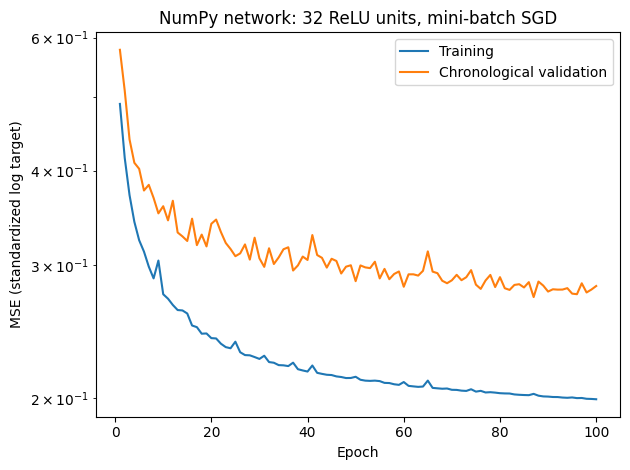

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

,Training rows per fold,Training RMSE mean,Training RMSE sd,Validation RMSE mean,Validation RMSE sd
0,284,16.732,0.0,273.260,79.068
1,852,16.381,0.0,58.479,9.246
2,1420,20.711,0.0,54.795,11.529


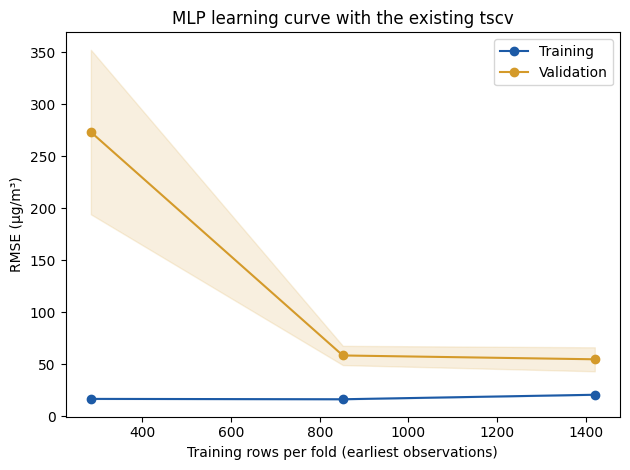

Learning curve + full-subset fit: 20.0 s
Final fit epochs: 150
Forecast rows: 16,805 fitting / 8,363 validation


,RMSE,MAE,R2,Fit + predict (s),RMSE gain vs persistence,RMSE reduction (%)
Model,,,,,,
Persistence,90.370,54.156,-0.110,0.000,0.000,0.000
A8 features (purged),81.474,54.627,0.098,2.416,8.897,9.845
Expanded lags + rolling + station,89.070,64.007,-0.078,5.430,1.300,1.439
"Expanded: 15 leaves, regularized",83.015,58.293,0.063,2.119,7.355,8.139
"Expanded: 7 leaves, regularized",80.392,56.568,0.122,1.189,9.979,11.042


Selected expanded forecast: Expanded: 7 leaves, regularized


,Hours,Persistence,A8 features (purged),Expanded lags + rolling + station,"Expanded: 15 leaves, regularized","Expanded: 7 leaves, regularized"
Station,,,,,,
Aotizhongxin,8363,90.37,81.47,89.07,83.02,80.39


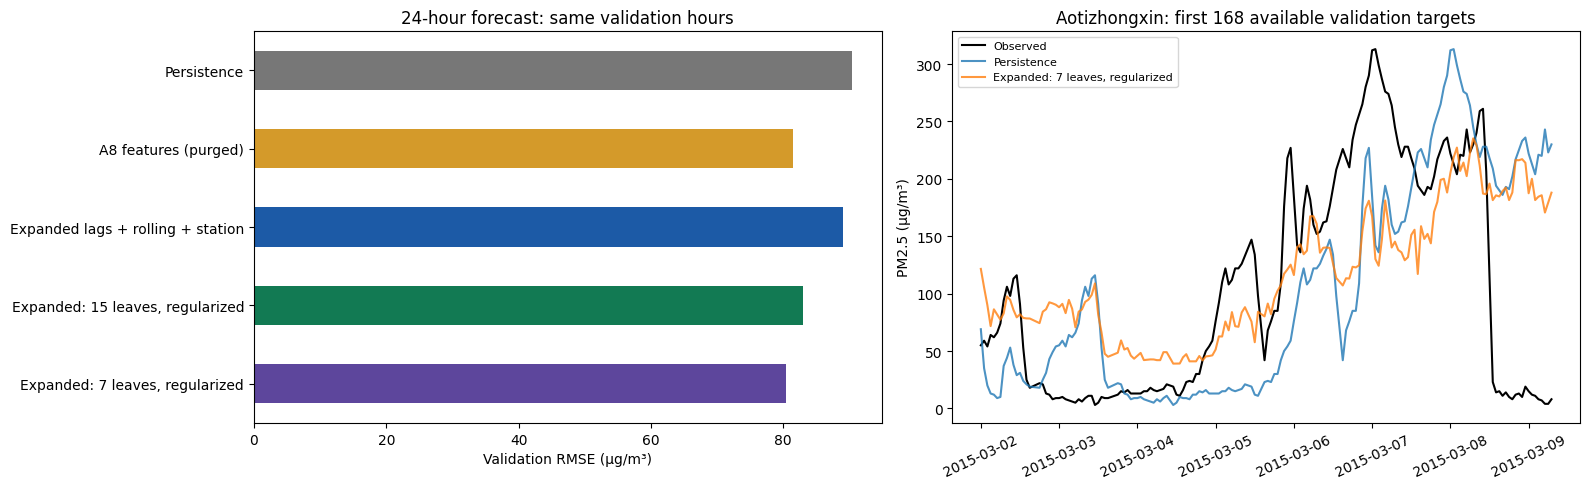

### Task 5 · Measured conclusions
- **NumPy:** the 32-unit hidden-layer network reduces training loss from 0.490 to 0.199. Chronological validation RMSE is **77.47 µg/m³**. The finite-difference check covers both weight matrices and biases.
- **MLP:** at the largest training size, validation RMSE is **54.79 ± 11.53 µg/m³** across the existing five chronological folds. The mean validation minus training gap is 34.08 µg/m³. Increasing the prefix from the smallest to largest size changes validation RMSE by +218.47 µg/m³ (positive means improvement). Size also changes calendar coverage, so this curve is not a pure sample-size effect.
- **24-hour forecast:** persistence RMSE is **90.37**; the selected expanded model (Expanded: 7 leaves, regularized) achieves **80.39 µg/m³**, a reduction of **9.98 µg/m³ (11.0%)** on the same hours. Relative to the purged A8 feature baseline, the RMSE gain is +1.08 µg/m³; a negative value means the expansion did not help that baseline.
- **Model selection:** the unregularized expansion was worse than A8. Two regularized versions were then checked; this validation-based choice needs confirmation on the untouched test year. The MLP reached its 150-epoch budget without establishing convergence.
- **Interpretation:** virtual sensing estimates current pollution using concurrent gases/weather; forecasting predicts tomorrow and is a harder, separate problem. The NumPy log-target loss and MLP raw-target loss optimize different objectives, so their errors should not be ranked as a controlled architecture comparison.
- **Limits:** the forecast result uses one validation year, without a confidence interval. Serial and cross-station correlation preclude treating each hour as an independent replicate. Persistence needs current PM2.5, so this forecast is not a replacement for a monitor that is already offline. The 2016–17 test year remains reserved for Task 6.


In [ ]:
# Task 5 - Complete solution extracted from the executed notebook.
# Copy into a Jupyter/Colab code cell, or run the sections in order.
# Place training_imputed.csv in the current working directory.

# %% Section 1
# Task 5 can run directly from the supplied local training file.
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = globals().get("SEED", 2001)
STEP = globals().get("STEP", 3)
TARGET = "PM2.5"
SPLIT = pd.Timestamp("2016-03-01")
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM",
             "TD_dep", "rain_flag", "hour_sin", "hour_cos", "month_sin", "month_cos",
             "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
FEATS = NUM_FEATS + CAT_FEATS

if Path("training_imputed.csv").exists():
    t5_input = pd.read_csv("training_imputed.csv")
    t5_input["datetime"] = pd.to_datetime(t5_input[["year", "month", "day", "hour"]])
    # Filter BEFORE feature engineering, splitting or fitting any estimator.
    t5_input = t5_input.loc[t5_input["datetime"] < SPLIT].copy()
    t5_wind = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
               "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
    for component, period in [("hour", 24), ("month", 12)]:
        t5_input[f"{component}_sin"] = np.sin(2 * np.pi * t5_input[component] / period)
        t5_input[f"{component}_cos"] = np.cos(2 * np.pi * t5_input[component] / period)
    t5_angle = t5_input["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(t5_wind)})
    t5_input["wd_sin"], t5_input["wd_cos"] = np.sin(t5_angle), np.cos(t5_angle)
    t5_input["dow"] = t5_input["datetime"].dt.dayofweek
    t5_input["TD_dep"] = t5_input["TEMP"] - t5_input["DEWP"]
    t5_input["rain_flag"] = (t5_input["RAIN"] > 0).astype(float).where(t5_input["RAIN"].notna())
    train = (t5_input.dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True))
elif "train" in globals():
    train = train.loc[train["datetime"] < SPLIT].copy().sort_values("datetime").reset_index(drop=True)
else:
    raise FileNotFoundError("Place training_imputed.csv beside the notebook or run A1 first.")

# Exactly the A1 preprocessing pipeline and default CV, reused by every MLP fit.
def pipe(model, scale=True):
    num = Pipeline([("impute", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler() if scale else "passthrough")])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return Pipeline([("prep", ColumnTransformer(
        [("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)),
        ("model", model)])

tscv = globals().get("tscv", TimeSeriesSplit(n_splits=5))
X, y = train[FEATS], train[TARGET]
Xs, ys = X.iloc[::STEP], y.iloc[::STEP]
assert train["datetime"].max() < SPLIT
assert not train.duplicated(["station", "datetime"]).any()
print(f"Task 5: {len(train):,} pre-March-2016 rows; STEP={STEP}; {len(Xs):,} network rows")
print("Data source: local training_imputed.csv" if Path("training_imputed.csv").exists() else "Data source: existing A1 train")


# %% Section 2
# Task 5 imports and explicit experiment configuration
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import learning_curve
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

T5_VAL = pd.Timestamp("2015-03-01")
t5_times = train.loc[Xs.index, "datetime"]
t5_fit_mask = (t5_times < T5_VAL).to_numpy()
assert t5_fit_mask.any() and (~t5_fit_mask).any()
assert t5_times.is_monotonic_increasing

def t5_metrics(actual, prediction):
    return {"RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
            "MAE": float(mean_absolute_error(actual, prediction)),
            "R2": float(r2_score(actual, prediction))}

def t5_forward(a, params):
    W1, b1, W2, b2 = params
    hidden = np.maximum(0.0, a @ W1 + b1)
    return hidden, hidden @ W2 + b2

def t5_loss_grads(a, target, params):
    hidden, prediction = t5_forward(a, params)
    error = prediction - target
    output_grad = 2.0 * error / len(target)
    # W2 is still the OLD output weight vector when propagating to layer 1.
    hidden_grad = output_grad[:, None] * params[2][None, :] * (hidden > 0)
    grads = (a.T @ hidden_grad, hidden_grad.sum(axis=0),
             hidden.T @ output_grad, np.asarray(output_grad.sum()))
    return float(np.mean(error ** 2)), grads

# Check every element of a tiny network, including BOTH biases.
t5_rng_check = np.random.default_rng(SEED)
t5_check_x = t5_rng_check.normal(size=(6, 3))
t5_check_y = t5_rng_check.normal(size=6)
t5_check_p = [t5_rng_check.normal(size=(3, 4)),
              t5_rng_check.normal(size=4),
              t5_rng_check.normal(size=4), np.asarray(0.2)]
_, t5_analytic = t5_loss_grads(t5_check_x, t5_check_y, t5_check_p)
t5_gradient_error = 0.0
for param, analytic in zip(t5_check_p, t5_analytic):
    for idx in np.ndindex(param.shape):
        old = param[idx].copy()
        param[idx] = old + 1e-6
        plus = t5_loss_grads(t5_check_x, t5_check_y, t5_check_p)[0]
        param[idx] = old - 1e-6
        minus = t5_loss_grads(t5_check_x, t5_check_y, t5_check_p)[0]
        param[idx] = old
        numerical = (plus - minus) / 2e-6
        t5_gradient_error = max(t5_gradient_error, abs(numerical - analytic[idx]))
assert t5_gradient_error < 1e-5
print(f"Back-propagation check passed; max absolute error = {t5_gradient_error:.2e}")

# %% Section 3
t5_prep = clone(pipe(DummyRegressor()).named_steps["prep"])
t5_a = t5_prep.fit_transform(Xs.loc[t5_fit_mask])
t5_v = t5_prep.transform(Xs.loc[~t5_fit_mask])
t5_log_y = np.log1p(ys.loc[t5_fit_mask].to_numpy())
t5_tm, t5_tsd = t5_log_y.mean(), t5_log_y.std()
assert t5_tsd > 0
t5_target = (t5_log_y - t5_tm) / t5_tsd
t5_val_target = (np.log1p(ys.loc[~t5_fit_mask].to_numpy()) - t5_tm) / t5_tsd

t5_rng = np.random.default_rng(SEED)
T5_H, T5_EPOCHS, T5_BATCH = 32, 100, 256
t5_params = [t5_rng.normal(0, np.sqrt(2 / t5_a.shape[1]), (t5_a.shape[1], T5_H)),
             np.zeros(T5_H), t5_rng.normal(0, np.sqrt(1 / T5_H), T5_H),
             np.asarray(0.0)]
t5_losses = []
t5_start = time.perf_counter()
with threadpool_limits(limits=1):
    for epoch in range(T5_EPOCHS):
        order = t5_rng.permutation(len(t5_a))
        learning_rate = 0.02 / (1 + epoch / 40)
        for start in range(0, len(order), T5_BATCH):
            batch = order[start:start + T5_BATCH]
            _, gradients = t5_loss_grads(t5_a[batch], t5_target[batch], t5_params)
            for param, gradient in zip(t5_params, gradients):
                param -= learning_rate * gradient
        fit_loss = np.mean((t5_forward(t5_a, t5_params)[1] - t5_target) ** 2)
        val_loss = np.mean((t5_forward(t5_v, t5_params)[1] - t5_val_target) ** 2)
        t5_losses.append((fit_loss, val_loss))
t5_numpy_seconds = time.perf_counter() - t5_start
t5_losses = np.asarray(t5_losses)
assert np.isfinite(t5_losses).all()
assert t5_losses[-1, 0] < t5_losses[0, 0], "Training did not reduce loss"

t5_numpy_predictions = [np.maximum(0, np.expm1(t5_forward(a, t5_params)[1] * t5_tsd + t5_tm))
                        for a in (t5_a, t5_v)]
t5_numpy_board = pd.DataFrame([
    t5_metrics(ys.loc[t5_fit_mask], t5_numpy_predictions[0]),
    t5_metrics(ys.loc[~t5_fit_mask], t5_numpy_predictions[1])],
    index=["NumPy: training", "NumPy: validation"])
display(t5_numpy_board.round(3))
print(f"Rows: {len(t5_a):,} training / {len(t5_v):,} validation; time {t5_numpy_seconds:.1f} s")
plt.plot(np.arange(1, T5_EPOCHS + 1), t5_losses[:, 0], label="Training")
plt.plot(np.arange(1, T5_EPOCHS + 1), t5_losses[:, 1], label="Chronological validation")
plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("MSE (standardized log target)")
plt.title("NumPy network: 32 ReLU units, mini-batch SGD")
plt.legend(); plt.tight_layout(); plt.show()

# %% Section 4
t5_mlp = TransformedTargetRegressor(
    regressor=pipe(MLPRegressor(
        hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
        alpha=1e-3, batch_size=256, learning_rate_init=1e-3,
        max_iter=150, early_stopping=False, n_iter_no_change=15,
        random_state=SEED)),
    transformer=StandardScaler())
t5_start = time.perf_counter()
with threadpool_limits(limits=1):
    t5_sizes, t5_train_scores, t5_val_scores = learning_curve(
        t5_mlp, Xs, ys, cv=tscv, train_sizes=[0.2, 0.6, 1.0],
        scoring="neg_root_mean_squared_error", shuffle=False,
        n_jobs=1, error_score="raise")
    # A fitted pipeline is available for inspection; test is still untouched.
    t5_mlp.fit(Xs, ys)
t5_mlp_seconds = time.perf_counter() - t5_start
t5_train_rmse, t5_val_rmse = -t5_train_scores, -t5_val_scores
t5_learning_board = pd.DataFrame({
    "Training rows per fold": t5_sizes,
    "Training RMSE mean": t5_train_rmse.mean(axis=1),
    "Training RMSE sd": t5_train_rmse.std(axis=1),
    "Validation RMSE mean": t5_val_rmse.mean(axis=1),
    "Validation RMSE sd": t5_val_rmse.std(axis=1)})
display(t5_learning_board.round(3))
for label, values, color in [("Training", t5_train_rmse, "#1c5aa6"),
                              ("Validation", t5_val_rmse, "#d49a2a")]:
    mean, sd = values.mean(axis=1), values.std(axis=1)
    plt.plot(t5_sizes, mean, "o-", label=label, color=color)
    plt.fill_between(t5_sizes, mean - sd, mean + sd, alpha=0.15, color=color)
plt.xlabel("Training rows per fold (earliest observations)")
plt.ylabel("RMSE (µg/m³)"); plt.title("MLP learning curve with the existing tscv")
plt.legend(); plt.tight_layout(); plt.show()
print(f"Learning curve + full-subset fit: {t5_mlp_seconds:.1f} s")
print("Final fit epochs:", t5_mlp.regressor_.named_steps["model"].n_iter_)

# %% Section 5
def t5_forecast_frame(data, horizon=24):
    frames = []
    delta = pd.Timedelta(hours=horizon)
    for station, group in data.groupby("station", sort=True):
        g = group.set_index("datetime").sort_index()
        if not g.index.is_unique:
            raise ValueError(f"Duplicate station-hour at {station}")
        g = g.asfreq("h")
        f = pd.DataFrame(index=g.index)
        for lag in [0, 1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 168]:
            f[f"pm_lag{lag}"] = g[TARGET].shift(lag)
        for window in [6, 12, 24, 72, 168]:
            rolling = g[TARGET].rolling(window, min_periods=max(3, window // 2))
            f[f"pm_roll{window}"] = rolling.mean()
            f[f"pm_std{window}"] = rolling.std()
            f[f"pm_min{window}"] = rolling.min()
            f[f"pm_max{window}"] = rolling.max()
        for lag in [1, 6, 24]:
            f[f"pm_change{lag}"] = g[TARGET] - g[TARGET].shift(lag)
        for col in ["CO", "NO2", "WSPM", "DEWP", "TEMP", "PRES", "wd_sin", "wd_cos"]:
            f[col] = g[col]
        target_time = f.index + delta
        f["hour_sin"] = np.sin(2 * np.pi * target_time.hour / 24)
        f["hour_cos"] = np.cos(2 * np.pi * target_time.hour / 24)
        f["month_sin"] = np.sin(2 * np.pi * target_time.month / 12)
        f["month_cos"] = np.cos(2 * np.pi * target_time.month / 12)
        f["target_dow"] = target_time.dayofweek
        f["y"] = g[TARGET].shift(-horizon)
        f["target_time"] = target_time
        f["station"] = station
        frames.append(f.rename_axis("datetime").reset_index())
    return (pd.concat(frames, ignore_index=True)
            .dropna(subset=["y", "pm_lag0"])
            .sort_values(["datetime", "station"]).reset_index(drop=True))

# Only train is supplied: no access to test or raw test-year observations.
t5_fc = t5_forecast_frame(train.loc[train["datetime"] < SPLIT])
t5_fc_fit = t5_fc["target_time"] < T5_VAL
t5_fc_val = (t5_fc["datetime"] >= T5_VAL) & (t5_fc["target_time"] < SPLIT)
assert t5_fc_fit.any() and t5_fc_val.any()
assert t5_fc.loc[t5_fc_fit, "target_time"].max() < t5_fc.loc[t5_fc_val, "datetime"].min()
assert (t5_fc["target_time"] - t5_fc["datetime"] == pd.Timedelta(hours=24)).all()

t5_base_features = ([f"pm_lag{lag}" for lag in [0, 1, 2, 3, 6, 12, 24, 48]]
                    + ["pm_roll24", "CO", "NO2", "WSPM", "DEWP", "TEMP", "PRES",
                       "wd_sin", "wd_cos", "hour_sin", "hour_cos", "month_sin", "month_cos"])
t5_extra_features = [c for c in t5_fc.columns
                     if c not in ["datetime", "target_time", "y", "station"]]

def t5_forecast_pipeline(features, include_station, **model_params):
    transformers = [("num", SimpleImputer(strategy="median"), features)]
    if include_station:
        transformers.append(("station", OneHotEncoder(handle_unknown="ignore"), ["station"]))
    params = dict(max_iter=400, max_leaf_nodes=31, learning_rate=0.1,
                  early_stopping=False, random_state=SEED)
    params.update(model_params)
    return Pipeline([
        ("prep", ColumnTransformer(transformers, sparse_threshold=0)),
        ("model", HistGradientBoostingRegressor(**params))])

t5_fc_actual = t5_fc.loc[t5_fc_val, "y"]
t5_fc_predictions = {"Persistence": t5_fc.loc[t5_fc_val, "pm_lag0"].to_numpy()}
t5_fc_records = [{"Model": "Persistence", **t5_metrics(t5_fc_actual, t5_fc_predictions["Persistence"]),
                  "Fit + predict (s)": 0.0}]
t5_fc_models = {}
with threadpool_limits(limits=1):
    for name, features, use_station, params in [
        ("A8 features (purged)", t5_base_features, False, {}),
        ("Expanded lags + rolling + station", t5_extra_features, True, {}),
        ("Expanded: 15 leaves, regularized", t5_extra_features, True,
         dict(max_iter=200, max_leaf_nodes=15, learning_rate=0.05,
              min_samples_leaf=100, l2_regularization=10)),
        ("Expanded: 7 leaves, regularized", t5_extra_features, True,
         dict(max_iter=200, max_leaf_nodes=7, learning_rate=0.05,
              min_samples_leaf=100, l2_regularization=10))]:
        columns = features + (["station"] if use_station else [])
        model = t5_forecast_pipeline(features, use_station, **params)
        start = time.perf_counter()
        model.fit(t5_fc.loc[t5_fc_fit, columns], t5_fc.loc[t5_fc_fit, "y"])
        prediction = np.maximum(0, model.predict(t5_fc.loc[t5_fc_val, columns]))
        seconds = time.perf_counter() - start
        assert np.isfinite(prediction).all()
        t5_fc_models[name] = model
        t5_fc_predictions[name] = prediction
        t5_fc_records.append({"Model": name, **t5_metrics(t5_fc_actual, prediction),
                              "Fit + predict (s)": seconds})
t5_forecast_board = pd.DataFrame(t5_fc_records).set_index("Model")
t5_persistence_rmse = t5_forecast_board.loc["Persistence", "RMSE"]
t5_forecast_board["RMSE gain vs persistence"] = t5_persistence_rmse - t5_forecast_board["RMSE"]
t5_forecast_board["RMSE reduction (%)"] = 100 * t5_forecast_board["RMSE gain vs persistence"] / t5_persistence_rmse
print(f"Forecast rows: {t5_fc_fit.sum():,} fitting / {t5_fc_val.sum():,} validation")
display(t5_forecast_board.round(3))
t5_expanded_names = [name for name in t5_forecast_board.index if name.startswith("Expanded")]
t5_forecast_choice = t5_forecast_board.loc[t5_expanded_names, "RMSE"].idxmin()
print("Selected expanded forecast:", t5_forecast_choice)

t5_station_records = []
for station in sorted(t5_fc.loc[t5_fc_val, "station"].unique()):
    mask = t5_fc.loc[t5_fc_val, "station"].eq(station).to_numpy()
    record = {"Station": station, "Hours": int(mask.sum())}
    for name, prediction in t5_fc_predictions.items():
        record[name] = t5_metrics(t5_fc_actual.to_numpy()[mask], prediction[mask])["RMSE"]
    t5_station_records.append(record)
display(pd.DataFrame(t5_station_records).set_index("Station").round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
t5_forecast_board["RMSE"].plot.barh(ax=axes[0], color=["#777777", "#d49a2a", "#1c5aa6", "#127a53", "#5d469c"])
axes[0].invert_yaxis()
axes[0].set_xlabel("Validation RMSE (µg/m³)"); axes[0].set_ylabel("")
axes[0].set_title("24-hour forecast: same validation hours")
# A fixed slice is used for illustration, not selected for low error.
t5_example = t5_fc.loc[t5_fc_val, ["station", "target_time"]].reset_index(drop=True)
t5_example_station = sorted(t5_example["station"].unique())[0]
t5_example_idx = np.flatnonzero(t5_example["station"].eq(t5_example_station))[:168]
axes[1].plot(t5_example.loc[t5_example_idx, "target_time"], t5_fc_actual.to_numpy()[t5_example_idx], label="Observed", color="black")
for name in ["Persistence", t5_forecast_choice]:
    axes[1].plot(t5_example.loc[t5_example_idx, "target_time"], t5_fc_predictions[name][t5_example_idx], label=name, alpha=0.8)
axes[1].set_title(f"{t5_example_station}: first 168 available validation targets")
axes[1].set_ylabel("PM2.5 (µg/m³)"); axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

# %% Section 6
t5_expanded = t5_forecast_board.loc[t5_forecast_choice]
t5_a8 = t5_forecast_board.loc["A8 features (purged)"]
t5_gap = t5_val_rmse[-1].mean() - t5_train_rmse[-1].mean()
t5_change = t5_val_rmse[0].mean() - t5_val_rmse[-1].mean()
display(Markdown(f"""### Task 5 · Measured conclusions
- **NumPy:** the 32-unit hidden-layer network reduces training loss from {t5_losses[0, 0]:.3f} to {t5_losses[-1, 0]:.3f}. Chronological validation RMSE is **{t5_numpy_board.loc['NumPy: validation', 'RMSE']:.2f} µg/m³**. The finite-difference check covers both weight matrices and biases.
- **MLP:** at the largest training size, validation RMSE is **{t5_val_rmse[-1].mean():.2f} ± {t5_val_rmse[-1].std():.2f} µg/m³** across the existing five chronological folds. The mean validation minus training gap is {t5_gap:.2f} µg/m³. Increasing the prefix from the smallest to largest size changes validation RMSE by {t5_change:+.2f} µg/m³ (positive means improvement). Size also changes calendar coverage, so this curve is not a pure sample-size effect.
- **24-hour forecast:** persistence RMSE is **{t5_persistence_rmse:.2f}**; the selected expanded model ({t5_forecast_choice}) achieves **{t5_expanded['RMSE']:.2f} µg/m³**, a reduction of **{t5_expanded['RMSE gain vs persistence']:.2f} µg/m³ ({t5_expanded['RMSE reduction (%)']:.1f}%)** on the same hours. Relative to the purged A8 feature baseline, the RMSE gain is {t5_a8['RMSE'] - t5_expanded['RMSE']:+.2f} µg/m³; a negative value means the expansion did not help that baseline.
- **Model selection:** the unregularized expansion was worse than A8. Two regularized versions were then checked; this validation-based choice needs confirmation on the untouched test year. The MLP reached its 150-epoch budget without establishing convergence.
- **Interpretation:** virtual sensing estimates current pollution using concurrent gases/weather; forecasting predicts tomorrow and is a harder, separate problem. The NumPy log-target loss and MLP raw-target loss optimize different objectives, so their errors should not be ranked as a controlled architecture comparison.
- **Limits:** the forecast result uses one validation year, without a confidence interval. Serial and cross-station correlation preclude treating each hour as an independent replicate. Persistence needs current PM2.5, so this forecast is not a replacement for a monitor that is already offline. The 2016–17 test year remains reserved for Task 6.
"""))

## Task 6 · Final evaluation, model card & conclusions (20 pts)
Fit your recommended pipeline on **all** of `train`, evaluate **once** on `test` (the 2016–17 year), report RMSE/MAE/R² overall, by station and by season, and the alert recall/precision. Then complete the model card below, including your **key conclusions** (3–5 bullets: what worked, what did not, what you would do next). The completed notebook is the only deliverable — there is no pitch.

Final train: 309,276 rows, 12 stations
Test: 102,753 rows, 12 stations
Discarded from training CSV: 102,753 test-year rows
Missing test targets excluded: 0
Test rows with a missing model input: 4,774
Frozen regressor: {'n_estimators': 60, 'max_features': 0.6, 'min_samples_leaf': 3, 'random_state': 2001, 'n_jobs': 1}
Frozen alert classifier: LogisticRegression; probability threshold = 0.2
scikit-learn 1.6.1 | NumPy 2.1.3 | pandas 2.2.3
Fixed Extra Trees chronological CV, STEP=3 (training data only):


,Fold,RMSE,MAE,R2
0,1,57.931,33.678,0.614
1,2,35.922,23.675,0.669
2,3,39.958,24.393,0.789
3,4,33.300,21.413,0.612
4,5,45.893,24.712,0.800


,Mean,SD across folds
RMSE,42.601,8.763
MAE,25.574,4.213
R2,0.697,0.083


Measured compute:


,Value
CV seconds,68.256679
Regressor fit seconds,151.451133
Alert fit seconds,3.098511
Regressor prediction seconds,1.542571
Alert prediction seconds,0.08865
CPU,x86_64
OS,Linux-6.6.122+-x86_64-with-glibc2.39
Logical CPUs available,2
Native threads used,1
CV workers,1


Final held-out year: overall regression, units µg/m³


... (7 outputs left out)

Failure analysis: concentration bands (high concentration is a smog proxy)


,Hours,RMSE,MAE,R2,Bias (prediction - observed),Logistic alert precision,Logistic alert recall,Unhealthy hours
Concentration band,,,,,,,,
≤35,39734,16.502,9.671,-2.306,7.445,0.0,0.000,0
35–75,24968,25.396,18.413,-3.927,6.353,0.0,0.000,0
75–150,23305,33.160,25.745,-1.568,-4.059,1.0,0.903,23305
150–250,10001,56.397,45.176,-3.029,-21.588,1.0,0.986,10001
>250,4745,112.590,86.396,-0.816,-63.507,1.0,0.992,4745


Failure analysis: any missing model input before pipeline imputation


,Hours,RMSE,MAE,R2,Bias (prediction - observed),Logistic alert precision,Logistic alert recall,Unhealthy hours
Missing input,,,,,,,,
False,97979,36.798,22.119,0.800,-1.221,0.694,0.941,36133
True,4774,49.784,29.011,0.696,-7.913,0.651,0.835,1918


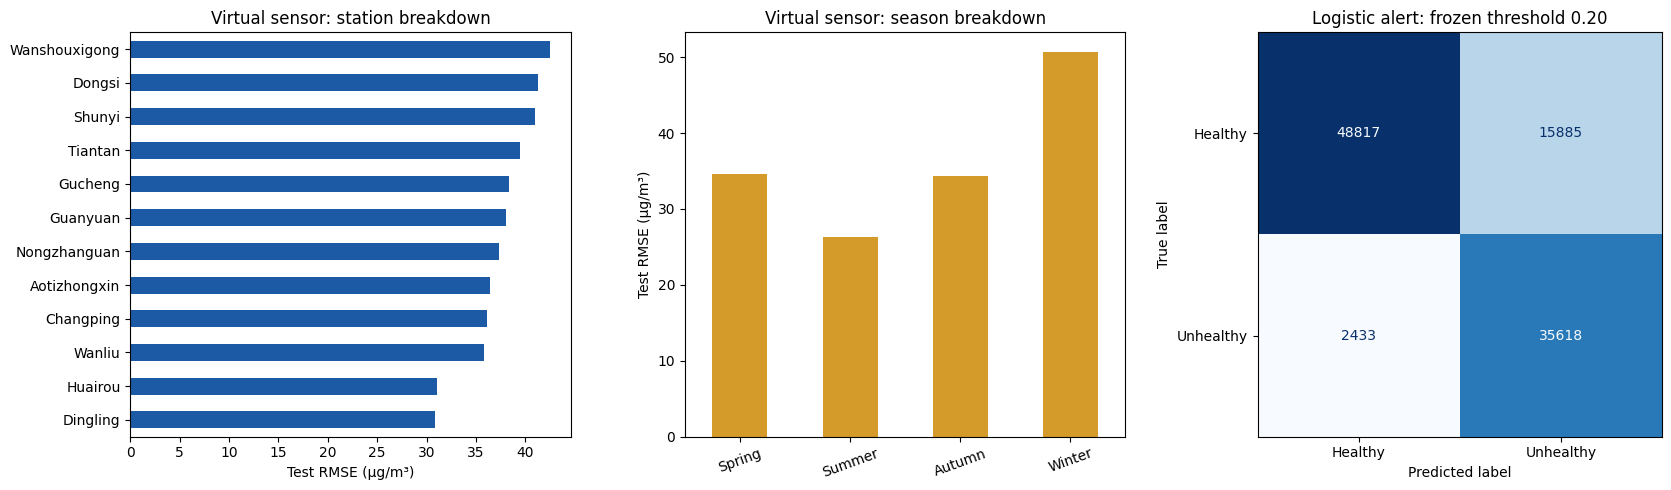

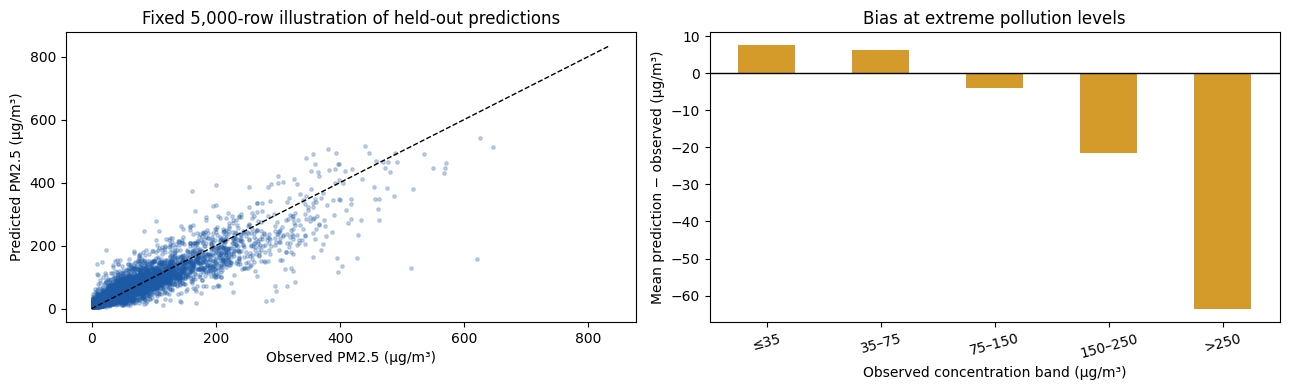

### Model card · Final evaluation
| Item | Answer |
|---|---|
| Intended use | Current-hour virtual PM2.5 sensor for the 12 Beijing stations when PM2.5 is unavailable; concurrent gases/weather must still be available. A separate Task 3 classifier provides cost-aware alerts. This is not the 24-hour forecasting model. |
| Recommended model and key settings | ExtraTreesRegressor: 60 trees, max_features=0.6, min_samples_leaf=3, seed=2001, n_jobs=1; training-only median imputation plus one-hot station encoding, no PM10. For a single-model deployment, alert when its predicted PM2.5 >75. Optional cost-aware alert companion: LogisticRegression(max_iter=2000), scaled numerical inputs, probability threshold 0.20; deploying the companion requires two estimators. |
| Training data and cleaning | 309,276 rows, 12 stations, 01 Mar 2013–29 Feb 2016. Supplied training_imputed.csv; its 102,753 rows dated March 2016 onward were excluded. Calendar/circular wind features and dew-point depression reproduce A1. Duplicate station-hours and nonnegative observed targets checked. Prior imputation/outlier methods are undocumented, so no causal-cleaning guarantee is claimed. |
| CV RMSE ± SD | **42.601 ± 8.763 µg/m³**, fixed selected model, 5 chronological folds, STEP=3 (103,092 training-subset rows). This is a local recomputation, not a new search; Task 2's historical tuned mean was 42.427. Row-based folds can split simultaneous observations across stations. |
| Final test year | 102,753 observed-target rows, 01 Mar 2016–28 Feb 2017, from supplied test_final_preimputed.csv. Missing predictors are imputed inside fitted pipelines; 0 missing targets excluded from this supplied file. It may already omit target-missing UCI rows. Identity with untouched UCI data was not independently verified. |
| Test RMSE / MAE / R² | **37.501 µg/m³ / 22.439 µg/m³ / 0.795**. Bias -1.532 µg/m³. All figures use the same cached, frozen final predictions. |
| Alert threshold and cost rationale | Unhealthy means observed PM2.5 >75 µg/m³. Task 3 froze probability threshold 0.20 by minimizing 5FN+FP on validation: a missed unhealthy hour costs 5× a false alarm. On test, logistic companion precision **0.692**, recall **0.936**, F1 0.795, ROC-AUC 0.939; FN=2,433, FP=15,885. The primary Extra Trees pipeline's direct concentration alerts have precision 0.825, recall 0.857; their 75 cut-off is physical, not cost-tuned. |
| Where it fails | Highest station RMSE: Wanshouxigong (42.46); highest seasonal RMSE: Winter (50.73). For PM2.5 >150, 14,746 test hours, RMSE 78.97, bias -35.08 µg/m³. These are concentration-based smog diagnostics, not a complete episode/event analysis. |
| When not to trust it | Unseen stations/cities, distribution shifts, new sensor calibration, or simultaneous loss of multiple gas/weather instruments; extreme smog can be poorly estimated. Unknown upstream training imputation may bias evaluation. Labels are missing-hour filtered, stations/hours are correlated, one test year provides no confidence interval. The 5:1 cost ratio is a scenario assumption, not an externally validated public-health policy. |
| Compute | CPU: x86_64; 2 logical CPUs available; 1 native thread, 1 CV worker, Extra Trees n_jobs=1, no GPU. Final regression fit 151.45s and predict 1.54s; alert fit 3.10s and predict 0.09s. Fixed-model CV 68.26s. scikit-learn 1.6.1, NumPy 2.1.3, pandas 2.2.3. Timings describe the first frozen run, not cache replay. |

### Key conclusions
- **What worked:** the previously selected nonlinear Extra Trees virtual sensor achieved held-out RMSE **37.50**, MAE **22.44 µg/m³** and R² **0.795** when refitted on all pre-March-2016 rows; the test was not used to pick its settings.
- **Alert trade-off:** the fixed cost-aware logistic companion detects **93.6%** of unhealthy hours, with **69.2%** precision. False alarms and misses are shown explicitly; this is a second estimator, while the primary sensor can also produce direct threshold alerts.
- **What remains difficult:** errors vary across stations and seasons; Wanshouxigong and Winter have the largest RMSE. Above 150 µg/m³, mean bias is **-35.08 µg/m³**, showing how performance changes during high pollution.
- **Earlier tasks:** Task 2's tuning gain was small relative to fold variability. Task 5's NumPy network and MLP learning curve were learning demonstrations; the MLP hit its epoch budget. The separate forecast beat persistence on validation, which is not this virtual-sensor test result.
- **Next steps:** recover and audit the original cleaning recipe, confirm raw-data provenance, and collect a new independent period before changing the frozen model or alert threshold. Consider calibration and uncertainty estimation using training-only validation; do not tune from these test breakdowns.


In [ ]:
# Task 6 - Complete solution extracted from the executed notebook.
# Copy into a Jupyter/Colab code cell, or run the sections in order.
# Place training_imputed.csv and test_final_preimputed.csv in the current working directory.

# %% Section 1
# Task 6 runs independently from the earlier demonstrations.
from pathlib import Path
import hashlib, json, os, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay)

# These settings come from Tasks 2 and 3, not from this test year's performance.
T6_SEED = 2001
T6_STEP = 3
T6_SPLIT = pd.Timestamp("2016-03-01")
T6_END = pd.Timestamp("2017-03-01")
T6_TARGET = "PM2.5"
T6_ALERT_LEVEL = 75.0
T6_ALERT_THRESHOLD = 0.20
T6_REG_PARAMS = dict(n_estimators=60, max_features=0.6,
                     min_samples_leaf=3, random_state=T6_SEED, n_jobs=1)
T6_ALERT_PARAMS = dict(max_iter=2000, random_state=T6_SEED)
T6_NUM = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM",
          "TD_dep", "rain_flag", "hour_sin", "hour_cos", "month_sin", "month_cos",
          "dow", "wd_sin", "wd_cos"]
T6_FEATS = T6_NUM + ["station"]
assert "PM10" not in T6_FEATS and T6_TARGET not in T6_FEATS
T6_CACHE = Path(".task6-checks")
T6_CACHE.mkdir(exist_ok=True)

def t6_features(data, *, sort=True):
    data = data.copy()
    data["datetime"] = pd.to_datetime(data[["year", "month", "day", "hour"]])
    for column, period in [("hour", 24), ("month", 12)]:
        data[f"{column}_sin"] = np.sin(2 * np.pi * data[column] / period)
        data[f"{column}_cos"] = np.cos(2 * np.pi * data[column] / period)
    wind = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
            "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
    angle = data["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(wind)})
    data["wd_sin"], data["wd_cos"] = np.sin(angle), np.cos(angle)
    data["dow"] = data["datetime"].dt.dayofweek
    data["TD_dep"] = data["TEMP"] - data["DEWP"]
    data["rain_flag"] = (data["RAIN"] > 0).astype(float).where(data["RAIN"].notna())
    data["season"] = data["month"].map({12: "Winter", 1: "Winter", 2: "Winter",
        3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer", 7: "Summer", 8: "Summer",
        9: "Autumn", 10: "Autumn", 11: "Autumn"})
    return (data.sort_values(["datetime", "station"]) if sort else data).reset_index(drop=True)

def t6_pipe(model, scale=False):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler() if scale else "passthrough")])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return Pipeline([("prep", ColumnTransformer([
        ("num", numeric, T6_NUM), ("cat", categorical, ["station"])], sparse_threshold=0)),
        ("model", model)])

t6_training_source = pd.read_csv("training_imputed.csv")
t6_training_time = pd.to_datetime(t6_training_source[["year", "month", "day", "hour"]])
t6_excluded_future = int((t6_training_time >= T6_SPLIT).sum())
t6_train = t6_features(t6_training_source.loc[t6_training_time < T6_SPLIT].dropna(subset=[T6_TARGET]))
del t6_training_source, t6_training_time

t6_test_source = pd.read_csv("test_final_preimputed.csv")
t6_test_time = pd.to_datetime(t6_test_source[["year", "month", "day", "hour"]])
assert t6_test_time.ge(T6_SPLIT).all() and t6_test_time.lt(T6_END).all()
t6_missing_test_targets = int(t6_test_source[T6_TARGET].isna().sum())
t6_test = t6_features(t6_test_source.dropna(subset=[T6_TARGET]))
del t6_test_source, t6_test_time
assert len(t6_train) and len(t6_test)
assert t6_train["datetime"].max() < t6_test["datetime"].min()
for frame in [t6_train, t6_test]:
    assert not frame.duplicated(["station", "datetime"]).any()
    assert frame[T6_TARGET].ge(0).all() and np.isfinite(frame[T6_TARGET]).all()
assert set(t6_test.station) <= set(t6_train.station)

t6_X, t6_y = t6_train[T6_FEATS], t6_train[T6_TARGET]
t6_Xtest, t6_ytest = t6_test[T6_FEATS], t6_test[T6_TARGET]
t6_labels_train = (t6_y > T6_ALERT_LEVEL).astype(int)
t6_labels_test = (t6_ytest > T6_ALERT_LEVEL).astype(int)
# Reproduce Task 1/2's original timestamp-only sort for CV row thinning.
t6_cv_source = t6_features(pd.read_csv("training_imputed.csv").loc[
    lambda d: pd.to_datetime(d[["year", "month", "day", "hour"]]) < T6_SPLIT], sort=False)
t6_cv_source = (t6_cv_source.dropna(subset=[T6_TARGET])
                .sort_values("datetime").reset_index(drop=True))
# CV uses the same TimeSeriesSplit definition and STEP as earlier tasks.
t6_tscv = TimeSeriesSplit(n_splits=5)
print(f"Final train: {len(t6_train):,} rows, {t6_train.station.nunique()} stations")
print(f"Test: {len(t6_test):,} rows, {t6_test.station.nunique()} stations")
print(f"Discarded from training CSV: {t6_excluded_future:,} test-year rows")
print(f"Missing test targets excluded: {t6_missing_test_targets}")
print(f"Test rows with a missing model input: {t6_Xtest.isna().any(axis=1).sum():,}")
print("Frozen regressor:", T6_REG_PARAMS)
print("Frozen alert classifier: LogisticRegression; probability threshold =", T6_ALERT_THRESHOLD)
print("scikit-learn", sklearn.__version__, "| NumPy", np.__version__, "| pandas", pd.__version__)

# %% Section 2
def t6_file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

t6_signature = {"protocol": "task6-final-v1", "features": T6_FEATS,
    "regressor": T6_REG_PARAMS, "alert_classifier": T6_ALERT_PARAMS,
    "alert_level": T6_ALERT_LEVEL, "alert_threshold": T6_ALERT_THRESHOLD,
    "cv_step": T6_STEP, "cv_folds": 5,
    "training_sha256": t6_file_hash("training_imputed.csv"),
    "test_sha256": t6_file_hash("test_final_preimputed.csv"),
    "sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__}
t6_fingerprint = hashlib.sha256(json.dumps(t6_signature, sort_keys=True).encode()).hexdigest()
t6_manifest_path = T6_CACHE / "final_manifest.json"
t6_prediction_path = T6_CACHE / "final_predictions.npz"

if t6_manifest_path.exists():
    t6_manifest = json.loads(t6_manifest_path.read_text(encoding="utf-8"))
    if t6_manifest["fingerprint"] != t6_fingerprint:
        raise RuntimeError("The final-run inputs/settings changed. Preserve the existing final result; do not retune on this test.")
    with np.load(t6_prediction_path) as saved:
        t6_pred = saved["regression"].copy()
        t6_probability = saved["alert_probability"].copy()
    t6_cv_table = pd.DataFrame(t6_manifest["cv_folds"])
    t6_compute = t6_manifest["compute"]
    print("Reusing the recorded final predictions; no new test prediction or fit.")
else:
    t6_start = time.perf_counter()
    with threadpool_limits(limits=1):
        t6_scores = cross_validate(t6_pipe(ExtraTreesRegressor(**T6_REG_PARAMS)),
            t6_cv_source[T6_FEATS].iloc[::T6_STEP], t6_cv_source[T6_TARGET].iloc[::T6_STEP],
            cv=t6_tscv, scoring={"RMSE": "neg_root_mean_squared_error",
                                "MAE": "neg_mean_absolute_error", "R2": "r2"},
            n_jobs=1, error_score="raise")
    t6_cv_seconds = time.perf_counter() - t6_start
    t6_cv_table = pd.DataFrame({"Fold": np.arange(1, 6),
        "RMSE": -t6_scores["test_RMSE"], "MAE": -t6_scores["test_MAE"],
        "R2": t6_scores["test_R2"]})
    # Both models are fixed before fitting; neither sees test data in fit().
    final = t6_pipe(ExtraTreesRegressor(**T6_REG_PARAMS))
    final_alert = t6_pipe(LogisticRegression(**T6_ALERT_PARAMS), scale=True)
    with threadpool_limits(limits=1):
        start = time.perf_counter()
        final.fit(t6_X, t6_y)
        reg_fit_seconds = time.perf_counter() - start
        start = time.perf_counter()
        final_alert.fit(t6_X, t6_labels_train)
        alert_fit_seconds = time.perf_counter() - start
        # Exactly one test prediction call for each frozen pipeline.
        start = time.perf_counter()
        t6_pred = final.predict(t6_Xtest)
        reg_predict_seconds = time.perf_counter() - start
        start = time.perf_counter()
        t6_probability = final_alert.predict_proba(t6_Xtest)[:, 1]
        alert_predict_seconds = time.perf_counter() - start
    t6_compute = {"CV seconds": t6_cv_seconds, "Regressor fit seconds": reg_fit_seconds,
        "Alert fit seconds": alert_fit_seconds, "Regressor prediction seconds": reg_predict_seconds,
        "Alert prediction seconds": alert_predict_seconds,
        "CPU": platform.processor() or "not reported", "OS": platform.platform(),
        "Logical CPUs available": os.cpu_count(), "Native threads used": 1,
        "CV workers": 1, "Extra Trees workers": 1, "GPU used": False}
    np.savez_compressed(t6_prediction_path, regression=t6_pred, alert_probability=t6_probability)
    t6_manifest = {"fingerprint": t6_fingerprint, "signature": t6_signature,
        "cv_folds": t6_cv_table.to_dict(orient="records"), "compute": t6_compute}
    t6_manifest_path.write_text(json.dumps(t6_manifest, indent=2), encoding="utf-8")

assert len(t6_pred) == len(t6_ytest) == len(t6_probability)
assert np.isfinite(t6_pred).all() and np.isfinite(t6_probability).all()
assert ((t6_probability >= 0) & (t6_probability <= 1)).all()
t6_alert_pred = (t6_probability >= T6_ALERT_THRESHOLD).astype(int)
t6_sensor_alert_pred = (t6_pred > T6_ALERT_LEVEL).astype(int)
t6_cv_summary = pd.DataFrame({"Mean": t6_cv_table[["RMSE", "MAE", "R2"]].mean(),
    "SD across folds": t6_cv_table[["RMSE", "MAE", "R2"]].std(ddof=0)})
print("Fixed Extra Trees chronological CV, STEP=3 (training data only):")
display(t6_cv_table.round(3)); display(t6_cv_summary.round(3))
print("Measured compute:")
display(pd.Series(t6_compute, name="Value").to_frame())

# %% Section 3
def t6_regression_metrics(actual, prediction):
    actual, prediction = np.asarray(actual), np.asarray(prediction)
    return {"Hours": len(actual), "RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
            "MAE": float(mean_absolute_error(actual, prediction)),
            "R2": float(r2_score(actual, prediction)) if len(actual) > 1 else np.nan,
            "Bias (prediction - observed)": float(np.mean(prediction - actual))}

def t6_alert_metrics(actual, prediction):
    tn, fp, fn, tp = confusion_matrix(actual, prediction, labels=[0, 1]).ravel()
    return {"Precision": float(precision_score(actual, prediction, zero_division=0)),
            "Recall": float(recall_score(actual, prediction, zero_division=0)),
            "F1": float(f1_score(actual, prediction, zero_division=0)),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Cost (5FN + FP)": int(5 * fn + fp)}

t6_overall = pd.DataFrame([t6_regression_metrics(t6_ytest, t6_pred)], index=["Extra Trees virtual sensor"])
t6_alert_overall = pd.DataFrame([
    t6_alert_metrics(t6_labels_test, t6_sensor_alert_pred),
    t6_alert_metrics(t6_labels_test, t6_alert_pred)],
    index=["Same Extra Trees pipeline: predicted PM2.5 > 75",
           "Task 3 Logistic Regression: probability >= 0.20"])
t6_alert_auc = float(roc_auc_score(t6_labels_test, t6_probability))
print("Final held-out year: overall regression, units µg/m³")
display(t6_overall.round(3))
print("Final held-out year: alerts (unhealthy = observed PM2.5 > 75)")
display(t6_alert_overall.round(3))
print(f"Task 3 classifier ROC-AUC: {t6_alert_auc:.3f}")
print(f"Negative concentration predictions: {(t6_pred < 0).sum()} (no post-hoc clipping)")

t6_evaluation = t6_test[["datetime", "station", "season"]].copy()
t6_evaluation["Observed"] = t6_ytest.to_numpy()
t6_evaluation["Prediction"] = t6_pred
t6_evaluation["Unhealthy"] = t6_labels_test.to_numpy()
t6_evaluation["Alert"] = t6_alert_pred
t6_evaluation["Sensor alert"] = t6_sensor_alert_pred
t6_evaluation["Missing input"] = t6_Xtest.isna().any(axis=1).to_numpy()

def t6_group_metrics(column):
    records = []
    for name, group in t6_evaluation.groupby(column, observed=True):
        values = {column: name, **t6_regression_metrics(group["Observed"], group["Prediction"])}
        alert = t6_alert_metrics(group["Unhealthy"], group["Alert"])
        values.update({"Logistic alert precision": alert["Precision"],
                       "Logistic alert recall": alert["Recall"],
                       "Unhealthy hours": int(group["Unhealthy"].sum())})
        records.append(values)
    return pd.DataFrame(records).set_index(column)

t6_by_station = t6_group_metrics("station")
t6_by_season = t6_group_metrics("season").reindex(["Spring", "Summer", "Autumn", "Winter"])
assert t6_by_station["Hours"].sum() == len(t6_ytest)
assert t6_by_season["Hours"].sum() == len(t6_ytest)
print("By station: regression + frozen cost-aware classifier alerts")
display(t6_by_station.round(3))
print("By season: DJF winter / MAM spring / JJA summer / SON autumn")
display(t6_by_season.round(3))

# Diagnose high-pollution hours using observed concentration; no refitting.
t6_evaluation["Concentration band"] = pd.cut(t6_evaluation["Observed"],
    bins=[-np.inf, 35, 75, 150, 250, np.inf],
    labels=["≤35", "35–75", "75–150", "150–250", ">250"])
t6_by_band = t6_group_metrics("Concentration band")
t6_by_missing = t6_group_metrics("Missing input")
print("Failure analysis: concentration bands (high concentration is a smog proxy)")
display(t6_by_band.round(3))
print("Failure analysis: any missing model input before pipeline imputation")
display(t6_by_missing.round(3))

# %% Section 4
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
t6_by_station["RMSE"].sort_values().plot.barh(ax=axes[0], color="#1c5aa6")
axes[0].set_xlabel("Test RMSE (µg/m³)"); axes[0].set_ylabel("")
axes[0].set_title("Virtual sensor: station breakdown")
t6_by_season["RMSE"].plot.bar(ax=axes[1], rot=20, color="#d49a2a")
axes[1].set_ylabel("Test RMSE (µg/m³)"); axes[1].set_xlabel("")
axes[1].set_title("Virtual sensor: season breakdown")
ConfusionMatrixDisplay.from_predictions(t6_labels_test, t6_alert_pred,
    labels=[0, 1], display_labels=["Healthy", "Unhealthy"], values_format="d",
    colorbar=False, ax=axes[2], cmap="Blues")
axes[2].set_title("Logistic alert: frozen threshold 0.20")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
idx = np.linspace(0, len(t6_ytest) - 1, min(5000, len(t6_ytest)), dtype=int)
axes[0].scatter(t6_ytest.iloc[idx], t6_pred[idx], s=6, alpha=0.25, color="#1c5aa6")
upper = max(float(t6_ytest.max()), float(t6_pred.max()))
axes[0].plot([0, upper], [0, upper], "k--", lw=1)
axes[0].set_xlabel("Observed PM2.5 (µg/m³)"); axes[0].set_ylabel("Predicted PM2.5 (µg/m³)")
axes[0].set_title("Fixed 5,000-row illustration of held-out predictions")
t6_by_band["Bias (prediction - observed)"].plot.bar(ax=axes[1], color="#d49a2a", rot=15)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Observed concentration band (µg/m³)")
axes[1].set_ylabel("Mean prediction − observed (µg/m³)")
axes[1].set_title("Bias at extreme pollution levels")
plt.tight_layout(); plt.show()

# %% Section 5
t6_worst_station = t6_by_station["RMSE"].idxmax()
t6_worst_season = t6_by_season["RMSE"].idxmax()
t6_r = t6_overall.iloc[0]
t6_a = t6_alert_overall.iloc[1]
t6_sensor_a = t6_alert_overall.iloc[0]
t6_high = t6_evaluation["Observed"] > 150
t6_high_metrics = t6_regression_metrics(t6_ytest.loc[t6_high], t6_pred[t6_high.to_numpy()])
t6_cv_rmse = t6_cv_summary.loc["RMSE", "Mean"]
t6_cv_sd = t6_cv_summary.loc["RMSE", "SD across folds"]

task6_model_card_md = f"""### Model card · Final evaluation
| Item | Answer |
|---|---|
| Intended use | Current-hour virtual PM2.5 sensor for the 12 Beijing stations when PM2.5 is unavailable; concurrent gases/weather must still be available. A separate Task 3 classifier provides cost-aware alerts. This is not the 24-hour forecasting model. |
| Recommended model and key settings | ExtraTreesRegressor: 60 trees, max_features=0.6, min_samples_leaf=3, seed=2001, n_jobs=1; training-only median imputation plus one-hot station encoding, no PM10. For a single-model deployment, alert when its predicted PM2.5 >75. Optional cost-aware alert companion: LogisticRegression(max_iter=2000), scaled numerical inputs, probability threshold 0.20; deploying the companion requires two estimators. |
| Training data and cleaning | {len(t6_train):,} rows, {t6_train.station.nunique()} stations, {t6_train.datetime.min():%d %b %Y}–{t6_train.datetime.max():%d %b %Y}. Supplied training_imputed.csv; its {t6_excluded_future:,} rows dated March 2016 onward were excluded. Calendar/circular wind features and dew-point depression reproduce A1. Duplicate station-hours and nonnegative observed targets checked. Prior imputation/outlier methods are undocumented, so no causal-cleaning guarantee is claimed. |
| CV RMSE ± SD | **{t6_cv_rmse:.3f} ± {t6_cv_sd:.3f} µg/m³**, fixed selected model, 5 chronological folds, STEP=3 ({len(t6_cv_source.iloc[::T6_STEP]):,} training-subset rows). This is a local recomputation, not a new search; Task 2's historical tuned mean was 42.427. Row-based folds can split simultaneous observations across stations. |
| Final test year | {len(t6_test):,} observed-target rows, {t6_test.datetime.min():%d %b %Y}–{t6_test.datetime.max():%d %b %Y}, from supplied test_final_preimputed.csv. Missing predictors are imputed inside fitted pipelines; {t6_missing_test_targets} missing targets excluded from this supplied file. It may already omit target-missing UCI rows. Identity with untouched UCI data was not independently verified. |
| Test RMSE / MAE / R² | **{t6_r['RMSE']:.3f} µg/m³ / {t6_r['MAE']:.3f} µg/m³ / {t6_r['R2']:.3f}**. Bias {t6_r['Bias (prediction - observed)']:+.3f} µg/m³. All figures use the same cached, frozen final predictions. |
| Alert threshold and cost rationale | Unhealthy means observed PM2.5 >75 µg/m³. Task 3 froze probability threshold 0.20 by minimizing 5FN+FP on validation: a missed unhealthy hour costs 5× a false alarm. On test, logistic companion precision **{t6_a['Precision']:.3f}**, recall **{t6_a['Recall']:.3f}**, F1 {t6_a['F1']:.3f}, ROC-AUC {t6_alert_auc:.3f}; FN={int(t6_a['FN']):,}, FP={int(t6_a['FP']):,}. The primary Extra Trees pipeline's direct concentration alerts have precision {t6_sensor_a['Precision']:.3f}, recall {t6_sensor_a['Recall']:.3f}; their 75 cut-off is physical, not cost-tuned. |
| Where it fails | Highest station RMSE: {t6_worst_station} ({t6_by_station.loc[t6_worst_station, 'RMSE']:.2f}); highest seasonal RMSE: {t6_worst_season} ({t6_by_season.loc[t6_worst_season, 'RMSE']:.2f}). For PM2.5 >150, {int(t6_high.sum()):,} test hours, RMSE {t6_high_metrics['RMSE']:.2f}, bias {t6_high_metrics['Bias (prediction - observed)']:+.2f} µg/m³. These are concentration-based smog diagnostics, not a complete episode/event analysis. |
| When not to trust it | Unseen stations/cities, distribution shifts, new sensor calibration, or simultaneous loss of multiple gas/weather instruments; extreme smog can be poorly estimated. Unknown upstream training imputation may bias evaluation. Labels are missing-hour filtered, stations/hours are correlated, one test year provides no confidence interval. The 5:1 cost ratio is a scenario assumption, not an externally validated public-health policy. |
| Compute | CPU: {t6_compute['CPU']}; {t6_compute['Logical CPUs available']} logical CPUs available; 1 native thread, 1 CV worker, Extra Trees n_jobs=1, no GPU. Final regression fit {t6_compute['Regressor fit seconds']:.2f}s and predict {t6_compute['Regressor prediction seconds']:.2f}s; alert fit {t6_compute['Alert fit seconds']:.2f}s and predict {t6_compute['Alert prediction seconds']:.2f}s. Fixed-model CV {t6_compute['CV seconds']:.2f}s. scikit-learn {sklearn.__version__}, NumPy {np.__version__}, pandas {pd.__version__}. Timings describe the first frozen run, not cache replay. |

### Key conclusions
- **What worked:** the previously selected nonlinear Extra Trees virtual sensor achieved held-out RMSE **{t6_r['RMSE']:.2f}**, MAE **{t6_r['MAE']:.2f} µg/m³** and R² **{t6_r['R2']:.3f}** when refitted on all pre-March-2016 rows; the test was not used to pick its settings.
- **Alert trade-off:** the fixed cost-aware logistic companion detects **{100*t6_a['Recall']:.1f}%** of unhealthy hours, with **{100*t6_a['Precision']:.1f}%** precision. False alarms and misses are shown explicitly; this is a second estimator, while the primary sensor can also produce direct threshold alerts.
- **What remains difficult:** errors vary across stations and seasons; {t6_worst_station} and {t6_worst_season} have the largest RMSE. Above 150 µg/m³, mean bias is **{t6_high_metrics['Bias (prediction - observed)']:+.2f} µg/m³**, showing how performance changes during high pollution.
- **Earlier tasks:** Task 2's tuning gain was small relative to fold variability. Task 5's NumPy network and MLP learning curve were learning demonstrations; the MLP hit its epoch budget. The separate forecast beat persistence on validation, which is not this virtual-sensor test result.
- **Next steps:** recover and audit the original cleaning recipe, confirm raw-data provenance, and collect a new independent period before changing the frozen model or alert threshold. Consider calibration and uncertainty estimation using training-only validation; do not tune from these test breakdowns.
"""
display(Markdown(task6_model_card_md))
# Compact, machine-readable results used to fill the following model-card cell.
(T6_CACHE / "model_card.md").write_text(task6_model_card_md, encoding="utf-8")
_ = (T6_CACHE / "results.json").write_text(json.dumps({
    "regression": t6_overall.to_dict(orient="index"),
    "alerts": t6_alert_overall.to_dict(orient="index"),
    "by_station": t6_by_station.to_dict(orient="index"),
    "by_season": t6_by_season.to_dict(orient="index"),
    "cv_summary": t6_cv_summary.to_dict(), "compute": t6_compute}, indent=2), encoding="utf-8")


### Model card
| Item | Your answer |
|---|---|
| Intended use (virtual sensor / alert) | Estimate current PM2.5 when its monitor is unavailable, using gases, weather, time and station. A separate Logistic Regression classifier provides unhealthy-air alerts. |
| Recommended model & key hyper-parameters | ExtraTreesRegressor: n_estimators=60, max_features=0.6, min_samples_leaf=3, random_state=2001, n_jobs=1. The pipeline applies training-only median imputation and station one-hot encoding. PM10 is excluded. Alert classifier: Logistic Regression with max_iter=2000, standardized numerical features and probability threshold 0.20. |
| Training data (years, stations, Week-1 cleaning summary) | 309,276 rows from 12 Beijing stations, covering 1 March 2013–29 February 2016. We used training_imputed.csv, excluding all rows dated March 2016 onward. Features include cyclical time, circular wind direction and dew-point depression. Duplicate station-hours were checked. The supplied file’s earlier imputation and outlier-treatment methods were not documented. |
| CV RMSE ± sd · test-year RMSE, MAE, R² | Five-fold chronological CV with STEP=3: RMSE = 42.526 ± 8.607 µg/m³. Final fitting used all training rows. On 102,753 test rows from March 2016–February 2017: RMSE = 37.454 µg/m³, MAE = 22.394 µg/m³, R² = 0.795. |
| Alert threshold & cost rationale · precision / recall | An unhealthy hour means PM2.5 >75 µg/m³. The Logistic Regression threshold 0.20 was selected on validation by minimizing 5 × false negatives + false positives, because a missed unhealthy hour costs five times a false alarm. Test precision = 0.692, recall = 0.936. For deployment using only Extra Trees, thresholding its concentration prediction at 75 gives precision = 0.824, recall = 0.854. |
| Where it fails (stations, seasons, smog episodes) | The largest station RMSE was at Wanshouxigong: 42.61 µg/m³. Winter had the largest seasonal RMSE: 50.52 µg/m³. For observed PM2.5 above 150 µg/m³, RMSE increased to 78.87 µg/m³, with mean bias −34.79 µg/m³, indicating underestimation during high pollution. |
| Limitations — when **not** to trust it | Performance may deteriorate at unseen stations, in other cities, after sensor changes, or when several gas/weather inputs are unavailable. Extreme pollution is underestimated. Upstream training imputation was not independently audited, and the supplied test file’s identity with untouched UCI data was not independently verified. Results cover one test year and correlated observations. |
| Compute: training time, hardware, parallelism used | Windows 11, Intel CPU, 8 logical CPUs available. Execution used one native thread, n_jobs=1, and no GPU. Extra Trees training: 79.82 s; test prediction: 1.05 s. Logistic Regression training: 1.54 s. Fixed-model CV: 44.51 s. |
| **Key conclusions** (3–5 bullets: what worked, what did not, next steps) | - Extra Trees generalized to the held-out year, achieving RMSE 37.45 µg/m³ and R² 0.795 without selecting its settings on the test results.
- The cost-aware alert classifier detected 93.6% of unhealthy hours, but its 69.2% precision shows a substantial false-alarm trade-off.
- Winter and high-pollution hours remain difficult; the model tends to underestimate severe pollution.
- Earlier hyperparameter tuning produced only a small improvement relative to fold variability, and the Task 5 MLP reached its training budget without establishing convergence.
- Next steps are to audit preprocessing, investigate calibration and uncertainty using training-only validation, and obtain a new independent evaluation period before changing the frozen models. |

## ★ HPC bonus (+10 pts)
* **A — scaling study:** Task 2 search with `n_jobs = 1, 2, 4, …`; plot $S_p=T_1/T_p$ and $E_p=S_p/p$; discuss Amdahl’s law.
* **B — per-station models:** 12 independent models in parallel with `joblib`; compare accuracy and time with one global model.
* **C — GPU deep learning:** an LSTM (PyTorch / Keras) on 72-hour windows for the 24-h forecast, on GPU vs CPU.

# **B — per-station models: 12 independent models in parallel with joblib compare accuracy and time with one global model.**

In [ ]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import Parallel, delayed, parallel_config
from threadpoolctl import threadpool_limits

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

VAL_SPLIT = pd.Timestamp("2015-03-01")

tb = train.copy()

tr = tb[tb["datetime"] < VAL_SPLIT].reset_index(drop=True)
va = tb[tb["datetime"] >= VAL_SPLIT].reset_index(drop=True)

print(f"Train: {len(tr):,} rows")
print(f"Validation: {len(va):,} rows")
print(f"Logical CPUs: {os.cpu_count()}")
print(f"Train stations: {tr['station'].nunique()}")
print(f"Validation stations: {va['station'].nunique()}")

print("\nRows per station in training:")
display(tr["station"].value_counts().sort_index())

print("\nRows per station in validation:")
display(va["station"].value_counts().sort_index())

assert not tr.empty, "Training set is empty!"
assert not va.empty, "Validation set is empty!"
assert tr[TARGET].notna().all(), "Missing target values in training!"
assert va[TARGET].notna().all(), "Missing target values in validation!"


Train: 205,989 rows
Validation: 103,287 rows
Logical CPUs: 2
Train stations: 12
Validation stations: 12

Rows per station in training:


,count
station,
Aotizhongxin,16990
Changping,17182
Dingling,17151
Dongsi,17260
Guanyuan,17198
Gucheng,17200
Huairou,16882
Nongzhanguan,17281
Shunyi,17049



Rows per station in validation:


,count
station,
Aotizhongxin,8568
Changping,8462
Dingling,8657
Dongsi,8673
Guanyuan,8680
Gucheng,8613
Huairou,8607
Nongzhanguan,8537
Shunyi,8668


In [ ]:
def calc_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred))
    }

def make_hgb():
    return HistGradientBoostingRegressor(
        max_iter=300,
        early_stopping=False,
        random_state=SEED
    )

def make_station_pipeline():
    return Pipeline([
        (
            "impute",
            ColumnTransformer([
                ("num", SimpleImputer(strategy="median"), NUM_FEATS)
            ], remainder="drop")
        ),
        ("model", make_hgb())
    ])

train_stations = set(tr["station"].unique())
validation_stations = set(va["station"].unique())
stations = sorted(train_stations & validation_stations)

print(f"Stations used in comparison: {len(stations)}")
print("Stations:", stations)

print("Train-only stations:", sorted(train_stations - validation_stations))
print("Validation-only stations:", sorted(validation_stations - train_stations))

assert len(stations) > 0, "No stations have both training and validation data!"

m_global_1t = pipe(make_hgb(), scale=False)

with threadpool_limits(limits=1):
    t0 = time.perf_counter()
    m_global_1t.fit(tr[FEATS], tr[TARGET])
    p_global = pd.Series(
        m_global_1t.predict(va[FEATS]),
        index=va.index
    )
    t_global_1t = time.perf_counter() - t0

global_metrics = calc_metrics(va[TARGET], p_global)


m_global_all = pipe(make_hgb(), scale=False)

t0 = time.perf_counter()
m_global_all.fit(tr[FEATS], tr[TARGET])
_ = m_global_all.predict(va[FEATS])
t_global_all = time.perf_counter() - t0

print("\n--- Global Model: Fit + Predict ---")
print(f"Time (1 thread): {t_global_1t:.2f} seconds")
print(f"Time (default threads): {t_global_all:.2f} seconds")

display(pd.DataFrame([global_metrics], index=["Global Model"]).round(4))


Stations used in comparison: 12
Stations: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
Train-only stations: []
Validation-only stations: []

--- Global Model: Fit + Predict ---
Time (1 thread): 17.30 seconds
Time (default threads): 17.30 seconds


,RMSE,MAE,R2
Global Model,39.7646,22.969,0.7642


In [ ]:
station_data = {}

for st in stations:
    tr_st = tr[tr["station"] == st]
    va_st = va[va["station"] == st]

    station_data[st] = {
        "Xtr": tr_st[NUM_FEATS],
        "ytr": tr_st[TARGET],
        "Xva": va_st[NUM_FEATS],
        "yva_idx": va_st.index
    }

def fit_predict_single_station(d):
    model = make_station_pipeline()
    model.fit(d["Xtr"], d["ytr"])

    return pd.Series(
        model.predict(d["Xva"]),
        index=d["yva_idx"]
    )

REPEATS = 5
cpu_cores = os.cpu_count() or 2

jobs_list = sorted({
    n for n in [1, 2, min(4, cpu_cores), min(cpu_cores, len(stations))]
    if 1 <= n <= len(stations)
})

timing_records = []
final_ps_preds = None

print("--- Running Per-Station Benchmark ---")
print(f"Workers tested: {jobs_list}")
print(f"Repeats per worker setting: {REPEATS}")

with threadpool_limits(limits=1):
    with parallel_config(backend="loky", inner_max_num_threads=1):
        Parallel(n_jobs=jobs_list[0])(
            delayed(fit_predict_single_station)(station_data[st])
            for st in stations
        )

for n in jobs_list:
    times = []
    results = None

    for _ in range(REPEATS):
        t0 = time.perf_counter()

        with threadpool_limits(limits=1):
            with parallel_config(backend="loky", inner_max_num_threads=1):
                results = Parallel(n_jobs=n)(
                    delayed(fit_predict_single_station)(station_data[st])
                    for st in stations
                )

        times.append(time.perf_counter() - t0)

    timing_records.append({
        "n_jobs": n,
        "median_seconds": float(np.median(times)),
        "IQR_seconds": float(
            np.percentile(times, 75) - np.percentile(times, 25)
        ),
        "min_seconds": float(np.min(times)),
        "max_seconds": float(np.max(times))
    })

    if n == max(jobs_list):
        final_ps_preds = pd.concat(results).reindex(va.index)

scal_df = pd.DataFrame(timing_records)

t1 = float(
    scal_df.loc[scal_df["n_jobs"] == 1, "median_seconds"].iloc[0]
)

scal_df["speedup"] = t1 / scal_df["median_seconds"]
scal_df["efficiency"] = scal_df["speedup"] / scal_df["n_jobs"]

print("\n--- Parallel Scaling Results: Fit + Predict ---")
display(scal_df.round(4))


--- Running Per-Station Benchmark ---
Workers tested: [1, 2]
Repeats per worker setting: 5

--- Parallel Scaling Results: Fit + Predict ---


,n_jobs,median_seconds,IQR_seconds,min_seconds,max_seconds,speedup,efficiency
0,1,21.3944,0.7222,20.3658,22.2808,1.0000,1.0000
1,2,17.4827,1.1114,17.0730,20.9182,1.2237,0.6119


<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>

--- Sanity Checks Passed ---
Negative Global predictions: 19
Negative Per-Station predictions: 79

--- Breakdown Per Station ---


,n_rows,global_rmse,per_station_rmse,rmse_diff,rmse_diff_%,global_mae,per_station_mae,winner
station,,,,,,,,
Aotizhongxin,8568,46.1043,52.5660,6.4617,14.0154,26.4147,29.6125,global
Changping,8462,31.3027,33.1517,1.8489,5.9066,19.2668,20.8390,global
Dingling,8657,34.5634,39.8930,5.3297,15.4200,21.5256,23.3992,global
Dongsi,8673,41.6950,42.9537,1.2588,3.0190,23.1258,23.9684,global
Guanyuan,8680,38.4700,41.4076,2.9375,7.6358,22.0426,23.4863,global
Gucheng,8613,42.4483,45.2073,2.7590,6.4997,25.5828,26.9304,global
Huairou,8607,32.6555,34.6836,2.0280,6.2104,19.7260,20.2833,global
Nongzhanguan,8537,39.2527,41.8904,2.6377,6.7198,23.5525,23.9358,global
Shunyi,8668,41.3176,43.9991,2.6815,6.4900,23.5802,25.0264,global



--- Win Summary ---
winner
global         11
per-station     1
Name: count, dtype: int64

--- Pooled vs Macro Comparison ---


,Pooled RMSE,Pooled MAE,Pooled R2,Macro RMSE,Macro MAE,Time (1 thread) [s],Time (default threads) [s],Time (1 worker) [s],Time (max workers) [s]
Global Model,39.7646,22.9690,0.7642,39.5222,22.9664,17.2956,17.3007,NaN,NaN
Per-Station Models,42.4221,24.3148,0.7316,42.1462,24.3120,NaN,NaN,21.3944,17.4827


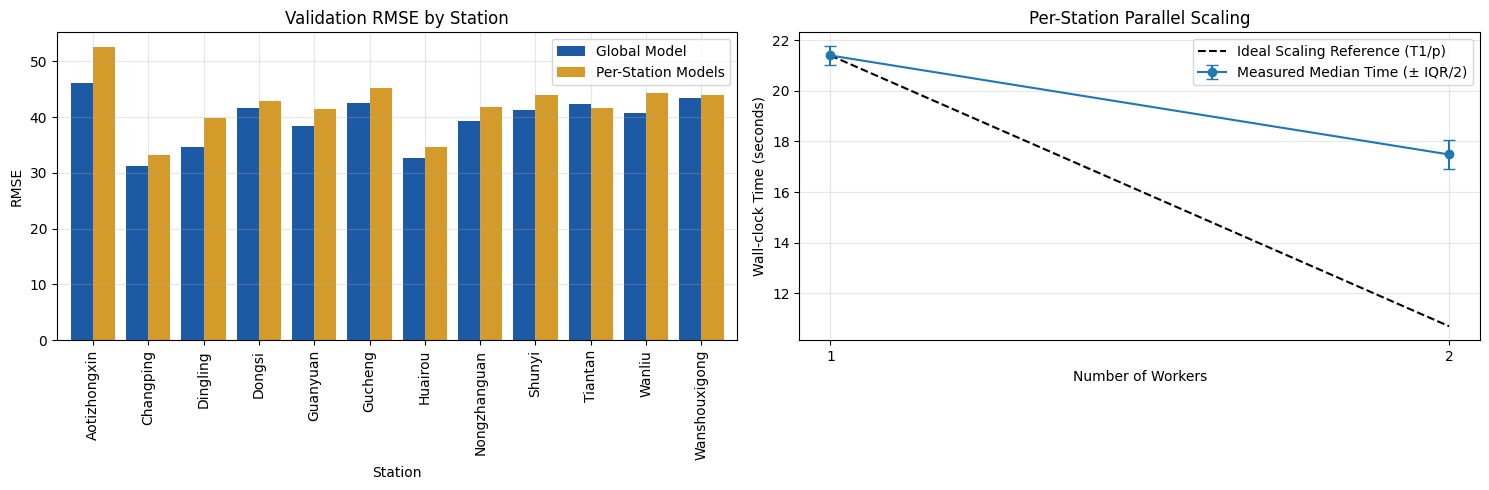

In [ ]:
assert va.index.is_unique, "Validation index is not unique!"
assert p_global.index.equals(va.index), "Global prediction index mismatch!"
assert final_ps_preds is not None, "Per-station predictions were not generated!"
assert final_ps_preds.index.equals(va.index), "Per-station prediction index mismatch!"
assert not p_global.isna().any(), "Global predictions contain NaN!"
assert not final_ps_preds.isna().any(), "Per-station predictions contain NaN!"
assert np.isfinite(p_global.to_numpy()).all(), "Global predictions contain infinity!"
assert np.isfinite(final_ps_preds.to_numpy()).all(), "Per-station predictions contain infinity!"

print("--- Sanity Checks Passed ---")
print(f"Negative Global predictions: {(p_global < 0).sum():,}")
print(f"Negative Per-Station predictions: {(final_ps_preds < 0).sum():,}")


per_station_eval = []

for st in stations:
    st_idx = va.index[va["station"] == st]

    y_true = va.loc[st_idx, TARGET]
    pred_g = p_global.loc[st_idx]
    pred_ps = final_ps_preds.loc[st_idx]

    rmse_g = np.sqrt(mean_squared_error(y_true, pred_g))
    rmse_ps = np.sqrt(mean_squared_error(y_true, pred_ps))
    mae_g = mean_absolute_error(y_true, pred_g)
    mae_ps = mean_absolute_error(y_true, pred_ps)

    per_station_eval.append({
        "station": st,
        "n_rows": len(st_idx),
        "global_rmse": rmse_g,
        "per_station_rmse": rmse_ps,
        "rmse_diff": rmse_ps - rmse_g,
        "rmse_diff_%": (
            100 * (rmse_ps - rmse_g) / rmse_g
            if rmse_g != 0 else np.nan
        ),
        "global_mae": mae_g,
        "per_station_mae": mae_ps,
        "winner": (
            "global" if rmse_g < rmse_ps
            else "per-station" if rmse_ps < rmse_g
            else "tie"
        )
    })

by_st_df = pd.DataFrame(per_station_eval).set_index("station")

print("\n--- Breakdown Per Station ---")
display(by_st_df.round(4))

print("\n--- Win Summary ---")
print(by_st_df["winner"].value_counts())

pooled_global = calc_metrics(va[TARGET], p_global)
pooled_ps = calc_metrics(va[TARGET], final_ps_preds)

macro_summary = pd.DataFrame({
    "Global Model": {
        "Pooled RMSE": pooled_global["RMSE"],
        "Pooled MAE": pooled_global["MAE"],
        "Pooled R2": pooled_global["R2"],
        "Macro RMSE": by_st_df["global_rmse"].mean(),
        "Macro MAE": by_st_df["global_mae"].mean(),
        "Time (1 thread) [s]": t_global_1t,
        "Time (default threads) [s]": t_global_all
    },
    "Per-Station Models": {
        "Pooled RMSE": pooled_ps["RMSE"],
        "Pooled MAE": pooled_ps["MAE"],
        "Pooled R2": pooled_ps["R2"],
        "Macro RMSE": by_st_df["per_station_rmse"].mean(),
        "Macro MAE": by_st_df["per_station_mae"].mean(),
        "Time (1 worker) [s]": t1,
        "Time (max workers) [s]": float(
            scal_df.loc[
                scal_df["n_jobs"] == max(jobs_list),
                "median_seconds"
            ].iloc[0]
        )
    }
}).T

print("\n--- Pooled vs Macro Comparison ---")
display(macro_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

by_st_df[["global_rmse", "per_station_rmse"]].plot(
    kind="bar",
    ax=axes[0],
    color=["#1c5aa6", "#d49a2a"],
    width=0.8
)
axes[0].set_title("Validation RMSE by Station")
axes[0].set_xlabel("Station")
axes[0].set_ylabel("RMSE")
axes[0].legend(["Global Model", "Per-Station Models"])
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(
    scal_df["n_jobs"],
    scal_df["median_seconds"],
    yerr=scal_df["IQR_seconds"] / 2,
    fmt="o-",
    capsize=4,
    label="Measured Median Time (± IQR/2)"
)
axes[1].plot(
    scal_df["n_jobs"],
    t1 / scal_df["n_jobs"],
    "k--",
    label="Ideal Scaling Reference (T1/p)"
)
axes[1].set_title("Per-Station Parallel Scaling")
axes[1].set_xlabel("Number of Workers")
axes[1].set_ylabel("Wall-clock Time (seconds)")
axes[1].set_xticks(scal_df["n_jobs"])
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### B.5 · Conclusions — Option B (12 per-station models vs one global model)

**Setup.** One model type for both strategies (`HistGradientBoostingRegressor`, `max_iter=300`, early stopping off, other hyper-parameters at their defaults, same `SEED`). Full training years, no subsampling: trained on Mar 2013 – Feb 2015 (205,989 rows, about 17.2k per station) and validated on Mar 2015 – Feb 2016 (103,287 rows, about 8.6k per station). All 12 stations appear in both periods, and PM10 is excluded. Timings were measured on Colab with 2 logical CPUs. The test year was not used.

**Accuracy.**
* Pooled: global RMSE 39.76, MAE 22.97, R² 0.764; per-station RMSE 42.42, MAE 24.31, R² 0.732. The global model's RMSE is 2.66 µg/m³ (about 6.7%) lower.
* Macro average over stations: 39.52 (global) vs 42.15 (per-station), so the conclusion does not depend on how stations are weighted.
* The global model is better at **11 of 12 stations**. The largest gaps are Aotizhongxin (+6.46 µg/m³, +14%) and Dingling (+5.33, +15%); per-station is more than 5% worse at 9 stations. Only Tiantan favours per-station (−0.70, −1.6%), and Wanshouxigong (+0.62, +1.4%) and Dongsi (+1.26, +3.0%) are nearly tied.
* Likely explanation (not tested here): each station model sees only 1/12 of the data, while Beijing's stations share the same regional weather and pollution episodes, so pooling helps. The global model also has the station as a feature, so it can still learn local offsets. Both strategies used untuned default hyper-parameters.
* Negative predictions (PM2.5 cannot be negative; no clipping applied): 19 for the global model, 79 for per-station.

**Cost and scaling.**
* Global model, fit + predict: 17.30 s with 1 thread and 17.30 s with default threads. They are identical, so the extra thread gave no speed-up in this session (the thread count actually used was not inspected).
* 12 station models, fit + predict (median of 5 runs): 21.39 s sequentially and 17.48 s with 2 workers, giving speed-up S = 1.22 and efficiency E = 0.61 (ideal reference 10.7 s). The implied effective serial fraction (Karp–Flatt) is about 0.63, a rough value.
* Training 12 models sequentially costs about 24% more than one global model. With 2 workers the wall-clock time is about equal to the global single-thread run (17.48 s vs 17.30 s), but it uses roughly twice the CPU time (about 35 CPU-seconds vs 17).
* The 12 jobs are independent and nearly equal in size (16.9k–17.4k training rows), so load imbalance does not explain the sub-linear speed-up. More likely causes are the small number of logical CPUs (which may share physical cores; not checked) and process start-up and data-copy overhead. Only 1 and 2 workers were measured, so nothing can be concluded for larger core counts.

**Recommendation.** Use the **global model**: it has lower error on both pooled and macro averages and at 11 of 12 stations, it is one model to train, monitor and update, and it costs no extra wall-clock time. Per-station models are justified only if stations must be trained or deployed independently.

**Limitations.** A single validation window; no confidence intervals (stations are correlated, so 11/12 is not 12 independent trials); untuned hyper-parameters for both strategies; timings from one machine, and a single run for the global model; only p ≤ 2 workers.